# Análisis NLP de los Planes Nacionales de Desarrollo (PND) de Colombia, 2006-2026

### **A. Rubiano Carlos Andrés**
### **Barrios Martínez Alexandra**

Este cuaderno construye un corpus con los PND de cinco gobiernos, lo segmenta en párrafos, lo etiqueta por temas con un diccionario de palabras clave y entrena un clasificador de temas (hasta el momento).

**Contenido**

| Parte | Sección | Resultado principal |
|---|---|---|
| I | Obtención de datos: scraping y descarga | PDF de los PND en `pnd_seleccion/` |
| II | Extracción de texto de los PDF | `.txt` por documento, `corpus_paginas.jsonl` y reporte de calidad |
| III | Segmentación en párrafos | `parrafos.jsonl` sin tablas, índices ni encabezados |
| IV | Etiquetado temático por diccionario | `segmentos_clasificados.csv/.xlsx` |
| V | Preparación de texto (preprocesamiento) | `segm_clasificados_limpios.csv` |
| VI | Distribución de clases y exploración semántica | Gráficas, POS, NER y nubes de palabras |
| VII | Modelado: vectorización TF-IDF y clasificación | Regresión logística, métricas y análisis de errores |

# Parte I · Obtención de datos: scraping y descarga

Se visitan las páginas del DNP de los cinco gobiernos objetivo (2006-2010, 2010-2014, 2014-2018, 2018-2022 y 2022-2026), se identifican los PDF de cada Plan Nacional de Desarrollo y se descargan los tomos seleccionados.

In [1]:
# Utilidades estándar: sistema de archivos, expresiones regulares y pausas
import os, re, time
# Peticiones HTTP y lectura de HTML (to parse)
import requests
import urllib3
from bs4 import BeautifulSoup
from urllib.parse import urljoin, unquote
from requests.exceptions import SSLError

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Silencia las advertencias por conexiones sin verificar SSL (ver función get)
urllib3.disable_warnings(urllib3.exceptions.InsecureRequestWarning)

## I.1 Configuración, scraping, filtrado y descarga

Esta celda hace todo el proceso en cuatro pasos:

1. **Gobiernos:** lee la página de históricos y detecta los enlaces de cada periodo.
2. **PDF de cada gobierno:** entra a la página de cada periodo y recolecta los enlaces `.pdf`.
3. **Filtrado:** se queda solo con los tomos definidos en `SELECCION`.
4. **Descarga:** guarda cada PDF en una carpeta por gobierno y valida que el archivo sea un PDF real.

In [2]:

# ================== CONFIGURACIÓN ==================
# Carpeta donde se guardarán los PDF descargados
CARPETA_BASE = "pnd_seleccion"

# Periodo de gobierno -> nombres de archivo (sin .pdf) de los tomos que se quieren descargar
SELECCION = {
    "2022-2026": ["plan-nacional-de-desarrollo-2022-2026-colombia-potencia-mundial-de-la-vida"],
    "2018-2022": ["tomo-1-dnp", "tomo-2-pnd"],
    "2014-2018": ["PND 2014-2018 Tomo 1 internet", "PND 2014-2018 Tomo 2 internet"],
    "2010-2014": ["PND2010-2014 Tomo I CD", "PND2010-2014 Tomo II CD"],
    "2006-2010": ["PND_Tomo_1", "PND_Tomo_2"],
}

# Listado histórico de PND y página del PND vigente (que no aparece en "Históricos")
URL_BASE = "https://www.dnp.gov.co/plan-nacional-desarrollo/Paginas/default.aspx"
URL_PND_ACTUAL = "https://www.dnp.gov.co/plan-nacional-desarrollo/Paginas/pnd-2022-2026.aspx"
# User-Agent de navegador para evitar bloqueos del servidor
HEADERS = {
    "User-Agent": "Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 "
                  "(KHTML, like Gecko) Chrome/120.0.0.0 Safari/537.36"
}

# ================== FUNCIONES ==================
# Sesión reutilizable: conserva cabeceras y conexiones entre peticiones
session = requests.Session()
session.headers.update(HEADERS)

# Elimina caracteres invisibles (zero-width, BOM) y espacios sobrantes
def limpiar(texto):
    return re.sub(r"[\u200b\u200c\u200d\ufeff]", "", texto).strip()

# Obtiene el nombre del archivo desde la URL, decodificado y sin la extensión .pdf
def nombre_sin_ext(url):
    return unquote(url.split("/")[-1]).rsplit(".pdf", 1)[0].strip()

def get(url, **kw):
    """GET con reintento sin verificación SSL si el certificado falla."""
    try:
        r = session.get(url, timeout=60, **kw)
    except SSLError:
        r = session.get(url, timeout=60, verify=False, **kw)
    r.raise_for_status()
    return r

def get_soup(url):
    return BeautifulSoup(get(url).text, "html.parser")

# Descarga el PDF por bloques (streaming) y valida que realmente sea un PDF
def descargar(url, ruta):
    r = get(url, stream=True)
    with open(ruta, "wb") as f:
        for chunk in r.iter_content(chunk_size=1024 * 64):
            f.write(chunk)
    # Un PDF válido empieza con la firma %PDF; si no, se borra el archivo y se lanza un error
    with open(ruta, "rb") as f:
        if not f.read(5).startswith(b"%PDF"):
            os.remove(ruta)
            raise ValueError("El archivo descargado no es un PDF válido")

# ================== 1) GOBIERNOS ==================
# Carga la página principal y busca enlaces con el formato "AAAA-AAAA - Presidente"
soup = get_soup(URL_BASE)
# Patrón del periodo de gobierno, p. ej. "2018-2022 - "
patron = re.compile(r"^(\d{4})\s*-\s*(\d{4})\s*-\s*")

# El PND actual se agrega a mano porque no está en la sección de históricos
gobiernos = [("2022-2026 - Gustavo Petro", URL_PND_ACTUAL)]   # no está en "Históricos"
# Recorre los enlaces de la página y conserva los que corresponden a un gobierno
for a in soup.find_all("a", href=True):
    texto = re.sub(r"\s+", " ", limpiar(a.get_text(" ", strip=True)))
    if patron.match(texto):
        gobiernos.append((texto, urljoin(URL_BASE, limpiar(a["href"]))))
# Elimina duplicados conservando el orden
gobiernos = list(dict.fromkeys(gobiernos))

# Solo los periodos que necesitas
gobiernos = [(g, u) for g, u in gobiernos if g[:9] in SELECCION]
print("Gobiernos a revisar:", [g for g, _ in gobiernos])

# ================== 2) PDFs DE CADA GOBIERNO ==================
# Para cada gobierno, recolecta los enlaces a PDF de su página
resultados = []
for gobierno, url_gob in gobiernos:
    try:
        s = get_soup(url_gob)
    except Exception as e:
        print(f"[ERROR] {gobierno}: {e}")
        continue
    # "vistos" evita registrar el mismo PDF dos veces
    vistos = set()
    for a in s.find_all("a", href=True):
        href = limpiar(a["href"])
        if ".pdf" not in href.lower():
            continue
        url_pdf = urljoin(url_gob, href)
        if url_pdf in vistos:
            continue
        vistos.add(url_pdf)
        resultados.append({"gobierno": gobierno, "url_pdf": url_pdf})
    print(f"{gobierno}: {len(vistos)} PDF(s)")
    # Pausa entre peticiones para no saturar el servidor
    time.sleep(1)

# ================== 3) FILTRAR ==================
# Conserva solo los PDF cuyo nombre coincide con los definidos en SELECCION
elegidos, encontrados = [], set()
for r in resultados:
    periodo = r["gobierno"][:9]
    nombre = nombre_sin_ext(r["url_pdf"])
    for buscado in SELECCION.get(periodo, []):
        if nombre.lower() == buscado.lower() and (periodo, buscado) not in encontrados:
            elegidos.append(r)
            encontrados.add((periodo, buscado))

# Avisa qué documentos de la selección no se encontraron en las páginas
for periodo, nombres in SELECCION.items():
    for n in nombres:
        if (periodo, n) not in encontrados:
            print(f"[NO ENCONTRADO] {periodo} -> {n}")

print(f"\nSeleccionados: {len(elegidos)} de {sum(len(v) for v in SELECCION.values())}")

# ================== 4) DESCARGAR ==================
# Crea una carpeta por gobierno y descarga cada PDF (omite los que ya existen)
fallidos = []
for i, r in enumerate(elegidos, 1):
    carpeta = os.path.join(CARPETA_BASE, re.sub(r'[\\/:*?"<>|]', "", r["gobierno"]))
    os.makedirs(carpeta, exist_ok=True)
    nombre = re.sub(r'[\\/:*?"<>|]', "_", unquote(r["url_pdf"].split("/")[-1]))
    ruta = os.path.join(carpeta, nombre)

    if os.path.exists(ruta):
        print(f"[{i}/{len(elegidos)}] ya existe: {ruta}")
        continue
    try:
        descargar(r["url_pdf"], ruta)
        print(f"[{i}/{len(elegidos)}] OK  {ruta}")
    except Exception as e:
        print(f"[{i}/{len(elegidos)}] ERROR {r['url_pdf']}\n    {e}")
        fallidos.append(r)
    # Pausa entre descargas
    time.sleep(1)

print(f"\nDescargados: {len(elegidos) - len(fallidos)} | Fallidos: {len(fallidos)}")
print("Ruta:", os.path.abspath(CARPETA_BASE))

Gobiernos a revisar: ['2022-2026 - Gustavo Petro', '2018-2022 - Iván Duque Márquez', '2014-2018 - Juan Manuel Santos', '2010-2014 - Juan Manuel Santos', '2006-2010 - Álvaro Uribe Vélez']
2022-2026 - Gustavo Petro: 22 PDF(s)
2018-2022 - Iván Duque Márquez: 17 PDF(s)
2014-2018 - Juan Manuel Santos: 4 PDF(s)
2010-2014 - Juan Manuel Santos: 25 PDF(s)
2006-2010 - Álvaro Uribe Vélez: 40 PDF(s)

Seleccionados: 9 de 9
[1/9] OK  pnd_seleccion/2022-2026 - Gustavo Petro/plan-nacional-de-desarrollo-2022-2026-colombia-potencia-mundial-de-la-vida.pdf
[2/9] OK  pnd_seleccion/2018-2022 - Iván Duque Márquez/tomo-1-dnp.pdf
[3/9] OK  pnd_seleccion/2018-2022 - Iván Duque Márquez/tomo-2-pnd.pdf
[4/9] OK  pnd_seleccion/2014-2018 - Juan Manuel Santos/PND 2014-2018 Tomo 1 internet.pdf
[5/9] OK  pnd_seleccion/2014-2018 - Juan Manuel Santos/PND 2014-2018 Tomo 2 internet.pdf
[6/9] OK  pnd_seleccion/2010-2014 - Juan Manuel Santos/PND2010-2014 Tomo I CD.pdf
[7/9] OK  pnd_seleccion/2010-2014 - Juan Manuel Santos/PN

# Parte II · Extracción de texto de los PDF

Se convierte cada PDF en texto limpio y se genera un reporte de calidad para detectar documentos problemáticos (por ejemplo, escaneados).

In [3]:
# Instala PyMuPDF (lectura de PDF) y pandas (tablas de resultados)
!pip install pymupdf pandas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 69.0/69.0 MB 57.1 MB/s  0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 136.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4/4 [pymupdf]


## II.1 Extracción, limpieza y reporte de calidad

Para cada PDF se extrae el texto página por página con PyMuPDF, se limpia (guiones de fin de línea, saltos de línea dentro de párrafos, encabezados y pies repetidos) y se guardan:

- un `.txt` por documento, con marcadores `[PÁGINA n]`,
- `corpus_paginas.jsonl`, con un registro por página y sus metadatos,
- `reporte_calidad.csv`, con métricas por documento (páginas sin texto, caracteres, líneas repetidas eliminadas).

In [4]:
# PyMuPDF lee los PDF; pandas arma el reporte de calidad
import re, json
from pathlib import Path
from collections import Counter
import pymupdf          # PyMuPDF (en versiones antiguas: import fitz)
import pandas as pd

# ---------- Configuración ----------
CARPETA_PDFS = Path("pnd_seleccion")   # la misma carpeta de la descarga
CARPETA_CORPUS = Path("corpus")
CARPETA_CORPUS.mkdir(exist_ok=True)
(CARPETA_CORPUS / "txt").mkdir(exist_ok=True)

MIN_CARACTERES = 50   # página con menos texto que esto se marca como "vacía"

# ---------- Limpieza ----------
# Limpia el texto de una página: quita guiones suaves, une palabras partidas y compacta espacios
def limpiar_texto(t):
    t = t.replace("\u00ad", "")                  # guion suave
    t = re.sub(r"-\n(?=[a-záéíóúñü])", "", t)    # palabras cortadas por guion al final de línea
    t = re.sub(r"(?<![.:;!?\n])\n(?!\n)", " ", t)  # une líneas dentro de un mismo párrafo
    # Colapsa espacios y limita los saltos de línea a un solo párrafo en blanco
    t = re.sub(r"[ \t]+", " ", t)
    t = re.sub(r"\n{3,}", "\n\n", t)
    return t.strip()

# Encuentra líneas que se repiten en muchas páginas (encabezados y pies de página)
def lineas_repetidas(paginas_texto, umbral=0.4):
    """Detecta encabezados/pies de página: líneas cortas que se repiten en muchas páginas."""
    n = len(paginas_texto)
    if n < 5:
        return set()
    cont = Counter()
    for t in paginas_texto:
        for linea in {l.strip() for l in t.split("\n") if 0 < len(l.strip()) < 80}:
            cont[linea] += 1
    return {l for l, c in cont.items() if c / n >= umbral}

# ---------- Metadatos desde el nombre de la carpeta ----------
# Separa periodo y presidente a partir del nombre de la carpeta
def parse_gobierno(nombre_carpeta):
    # "2018-2022 - Iván Duque Márquez"
    m = re.match(r"(\d{4}-\d{4})\s*-\s*(.+)", nombre_carpeta)
    return (m.group(1), m.group(2).strip()) if m else (nombre_carpeta, "")

# ---------- Procesamiento ----------
registros = []   # un dict por página
reporte = []     # un dict por documento

# Recorre todos los PDF: extrae, limpia y registra cada página
for pdf_path in sorted(CARPETA_PDFS.rglob("*.pdf")):
    periodo, presidente = parse_gobierno(pdf_path.parent.name)

    # sort=True ordena los bloques de texto en orden de lectura
    with pymupdf.open(pdf_path) as doc:
        crudo = [p.get_text("text", sort=True) for p in doc]

    # Detecta los encabezados/pies del documento para eliminarlos
    repetidas = lineas_repetidas(crudo)
    paginas_vacias = 0
    textos_doc = []

    # Limpia cada página y guarda un registro con sus metadatos
    for i, t in enumerate(crudo, 1):
        t = "\n".join(l for l in t.split("\n") if l.strip() not in repetidas)
        t = limpiar_texto(t)
        # Cuenta las páginas casi sin texto (posibles escaneos, portadas o páginas en blanco)
        if len(t) < MIN_CARACTERES:
            paginas_vacias += 1
        registros.append({
            "periodo": periodo,
            "presidente": presidente,
            "documento": pdf_path.stem,
            "pagina": i,
            "n_caracteres": len(t),
            "texto": t,
        })
        textos_doc.append(t)

    # .txt por documento, con marcador de página
    salida = CARPETA_CORPUS / "txt" / f"{periodo}__{pdf_path.stem}.txt"
    salida.write_text(
        "\n\n".join(f"[PÁGINA {i}]\n{t}" for i, t in enumerate(textos_doc, 1)),
        encoding="utf-8",
    )

    # Métricas de calidad por documento
    reporte.append({
        "periodo": periodo,
        "documento": pdf_path.stem,
        "paginas": len(crudo),
        "paginas_sin_texto": paginas_vacias,
        "pct_sin_texto": round(100 * paginas_vacias / max(len(crudo), 1), 1),
        "caracteres": sum(len(t) for t in textos_doc),
        "lineas_repetidas_eliminadas": len(repetidas),
    })
    print(f"✔ {periodo} | {pdf_path.name} | {len(crudo)} págs | {paginas_vacias} sin texto")

# ---------- Guardar ----------
# JSONL: un registro JSON por línea (una página por registro)
with open(CARPETA_CORPUS / "corpus_paginas.jsonl", "w", encoding="utf-8") as f:
    for r in registros:
        f.write(json.dumps(r, ensure_ascii=False) + "\n")

df_reporte = pd.DataFrame(reporte)
df_reporte.to_csv(CARPETA_CORPUS / "reporte_calidad.csv", index=False, encoding="utf-8-sig")
print("\n", df_reporte.to_string(index=False))
print("\nCorpus en:", CARPETA_CORPUS.resolve())

✔ 2006-2010 | PND_Tomo_1.pdf | 440 págs | 21 sin texto
✔ 2006-2010 | PND_Tomo_2.pdf | 300 págs | 16 sin texto
✔ 2010-2014 | PND2010-2014 Tomo I CD.pdf | 541 págs | 12 sin texto
✔ 2010-2014 | PND2010-2014 Tomo II CD.pdf | 481 págs | 14 sin texto
✔ 2014-2018 | PND 2014-2018 Tomo 1 internet.pdf | 550 págs | 26 sin texto
✔ 2014-2018 | PND 2014-2018 Tomo 2 internet.pdf | 680 págs | 20 sin texto
✔ 2018-2022 | tomo-1-dnp.pdf | 910 págs | 29 sin texto
✔ 2018-2022 | tomo-2-pnd.pdf | 1050 págs | 40 sin texto
✔ 2022-2026 | plan-nacional-de-desarrollo-2022-2026-colombia-potencia-mundial-de-la-vida.pdf | 848 págs | 19 sin texto

   periodo                                                                  documento  paginas  paginas_sin_texto  pct_sin_texto  caracteres  lineas_repetidas_eliminadas
2006-2010                                                                 PND_Tomo_1      440                 21            4.8     1323522                            1
2006-2010                            

## II.2 Verificación rápida del corpus

Se carga el corpus por páginas y se cuentan las palabras por gobierno para comprobar que la extracción funcionó.

In [5]:
# Carga el corpus por páginas (un registro por línea)
df = pd.read_json("corpus/corpus_paginas.jsonl", lines=True)

# Texto completo de un gobierno
texto_duque = "\n".join(df[df.periodo == "2018-2022"].texto)

# Palabras por gobierno
# Conteo de palabras por página y total por gobierno
df["n_palabras"] = df.texto.str.split().str.len()
df.groupby("periodo").n_palabras.sum()

,n_palabras
periodo,
2006-2010,328583
2010-2014,385289
2014-2018,423781
2018-2022,703491
2022-2026,272514


# Parte III · Segmentación del corpus en párrafos

A partir de los `.txt` se construyen segmentos de texto aptos para el análisis. Las reglas de depuración se describen en la siguiente celda.

## III.1 Detección de tablas, índices y encabezados, y segmentación

Esta celda aplica las reglas anteriores en tres etapas:

1. **Exclusión de páginas:** descarta páginas de índice (puntos guía, encabezados de índice) y páginas de tablas (heurística de proporción numérica y escasez de oraciones).
2. **Limpieza de bloques:** elimina encabezados y pies repetidos, números de página sueltos y bloques de menos de 20 palabras.
3. **Segmentación:** conserva los párrafos y divide por oraciones los que superan 2.000 caracteres.

Salidas: `parrafos.jsonl`, `paginas_excluidas.csv` y `resumen_segmentacion.csv`.

In [6]:
# math.ceil se usa para repartir párrafos largos en trozos parejos
import re, json, math
from pathlib import Path
from collections import Counter
import pandas as pd

# ================== CONFIGURACIÓN ==================
CARPETA_CORPUS = Path("corpus")
CARPETA_TXT    = CARPETA_CORPUS / "txt"
CARPETA_PDFS   = Path("pnd_seleccion")

# Parámetros de segmentación
MIN_PALABRAS   = 20      # bloques con menos palabras se descartan
MAX_CARACTERES = 2000    # párrafos más largos se dividen por oraciones

# Detección de tablas (heurística sobre el texto)
UMBRAL_NUMERICO  = 0.35  # % de tokens numéricos para marcar tabla directamente
UMBRAL_NUM_MIXTO = 0.15  # % numérico mínimo si además casi no hay oraciones
MAX_PUNTOS_X100  = 1.5   # puntos finales por cada 100 palabras (prosa suele tener 4-8)
USAR_PDF_TABLAS  = False # True: refuerza con PyMuPDF find_tables() (más lento)

# Encabezados / pies repetidos
UMBRAL_REPETIDO  = 0.10  # un bloque en el borde de ≥10% de las páginas = encabezado/pie

# ================== UTILIDADES ==================
# Marcador "[PÁGINA n]" escrito en los .txt por la celda anterior
PAG_RE   = re.compile(r"^\[PÁGINA (\d+)\]\n", re.M)
# Token numérico (cifras, porcentajes, rangos, montos)
NUM_RE   = re.compile(r"^[\(\$]?\d[\d.,%/\-–)]*$")
# Bloque que es solo un número de página ("12", "iv", "pág. 3", "3 de 120")
SOLO_NUM = re.compile(r"^(?:p[áa]g(?:ina)?\.?\s*)?(?:\d{1,4}|[ivxlcdm]{1,6})(?:\s*(?:de|/)\s*\d+)?$", re.I)
# Puntos guía típicos de un índice (".....12")
LIDER    = re.compile(r"(?:\.\s?){4,}|…{2,}")          # puntos guía de índices ".....12"
# Encabezados de índice y de listas de tablas, figuras, siglas, etc.
HEAD_IDX = re.compile(
    r"^\s*(índice|indice|contenido|contenidos|tabla de contenidos?|"
    r"(lista|índice) de (tablas|gráficos|graficos|figuras|cuadros|mapas|siglas))\b", re.I)

# Lee un .txt y devuelve una lista de tuplas (número de página, texto)
def leer_paginas(path):
    partes = PAG_RE.split(path.read_text(encoding="utf-8"))
    return [(int(partes[i]), partes[i + 1].strip()) for i in range(1, len(partes) - 1, 2)]

# Divide el texto de una página en bloques (cada línea no vacía es un bloque)
def bloques(texto):
    return [b.strip() for b in re.split(r"\n+", texto) if b.strip()]

# Minúsculas y dígitos reemplazados por "#": así se comparan encabezados que solo cambian de número
def normalizar(b):
    return re.sub(r"\d+", "#", b.lower()).strip()

# Separa periodo y presidente a partir del nombre de la carpeta
def parse_gobierno(nombre):
    m = re.match(r"(\d{4}-\d{4})\s*-\s*(.+)", nombre)
    return (m.group(1), m.group(2).strip()) if m else (nombre, "")

# ================== 1) TABLAS ==================
# Devuelve (n.º de palabras, proporción de tokens numéricos, puntos finales por cada 100 palabras)
def metricas(texto):
    palabras = texto.split()
    n = len(palabras)
    if n == 0:
        return 0, 0.0, 0.0
    r_num = sum(bool(NUM_RE.match(p)) for p in palabras) / n
    # La prosa tiene muchos puntos finales; las tablas casi ninguno
    puntos = len(re.findall(r"[.!?](?:\s|$)", texto)) * 100 / n
    return n, r_num, puntos

# Heurística: es tabla si tiene muchos números y pocas oraciones, o un rótulo "Tabla/Cuadro/Gráfico n"
def es_tabla_texto(texto):
    n, r_num, puntos = metricas(texto)
    if n < 15:
        return False
    # Busca un rótulo de tabla o gráfico al inicio de la página
    rotulo = bool(re.search(r"\b(Tabla|Cuadro|Gráfico|Grafico)\s+\d", texto[:300]))
    return (
        r_num >= UMBRAL_NUMERICO
        or (r_num >= UMBRAL_NUM_MIXTO and puntos < MAX_PUNTOS_X100)
        or (rotulo and r_num >= 0.10 and puntos < 3)
    )

# Opcional (USAR_PDF_TABLAS): usa find_tables() de PyMuPDF y marca páginas donde las tablas ocupan ≥20 % del área
def paginas_con_tablas_pdf(pdf_path):
    import pymupdf
    marcadas = set()
    with pymupdf.open(pdf_path) as doc:
        for i, page in enumerate(doc, 1):
            try:
                tablas = [t for t in page.find_tables().tables
                          if t.row_count >= 3 and t.col_count >= 2]
            except Exception:
                continue
            area = sum((t.bbox[2] - t.bbox[0]) * (t.bbox[3] - t.bbox[1]) for t in tablas)
            if area / (page.rect.width * page.rect.height) >= 0.20:
                marcadas.add(i)
    return marcadas

# ================== 2) ÍNDICES, ENCABEZADOS Y PIES ==================
# Una página es índice si tiene ≥3 puntos guía, o si inicia con un encabezado de índice y tiene al menos uno
def es_indice(texto):
    bl = bloques(texto)
    if not bl:
        return False
    lideres = len(LIDER.findall(texto))
    return lideres >= 3 or (bool(HEAD_IDX.match(bl[0])) and lideres >= 1)

def bloques_repetidos(paginas):
    """Bloques cortos que aparecen en los bordes de muchas páginas (dígitos normalizados)."""
    n = len(paginas)
    if n < 10:
        return set()
    cont = Counter()
    for _, t in paginas:
        bl = bloques(t)
        bordes = bl[:2] + bl[-2:]
        for b in {normalizar(x) for x in bordes if len(x.split()) < 15}:
            cont[b] += 1
    return {b for b, c in cont.items() if b and c / n >= UMBRAL_REPETIDO}

# ================== 3-4) PÁRRAFOS Y ORACIONES ==================
# Abreviaturas cuyo punto NO marca el fin de una oración
ABREV = r"(?:Dra?|Sra?|No|Nº|N°|núm|Arts?|arts?|págs?|pp|Fig|Cap|cap|vs|Vol|vol|Ed|ed|Av|Cra|Cll|Inc|Ltda|EE|UU|aprox|ej|Mg|Ing|Lic|Prof|Gral|Cel|Dir|Min)"

# Separa un texto en oraciones, protegiendo abreviaturas e iniciales
def separar_oraciones(texto):
    t = re.sub(rf"\b({ABREV})\.", r"\1§", texto)                  # protege abreviaturas
    t = re.sub(r"\b([A-ZÁÉÍÓÚÑ])\.(?=\s)", r"\1§", t)            # protege iniciales (J. M.)
    partes = re.split(r"(?<=[.!?…])\s+(?=[A-ZÁÉÍÓÚÑ¿¡«“\"(\[\d])", t)
    return [p.replace("§", ".").strip() for p in partes if p.strip()]

# Divide un párrafo largo en trozos de tamaño parejo (< MAX_CARACTERES), cortando en límites de oración
def dividir_por_oraciones(texto):
    if len(texto) <= MAX_CARACTERES:
        return [texto]
    oraciones = separar_oraciones(texto)
    n = math.ceil(len(texto) / MAX_CARACTERES)
    objetivo = len(texto) / n                       # trozos de tamaño parejo
    trozos, actual = [], ""
    for o in oraciones:
        candidato = f"{actual} {o}".strip()
        if actual and (len(candidato) > MAX_CARACTERES or len(actual) >= objetivo):
            trozos.append(actual)
            actual = o
        else:
            actual = candidato
    if actual:
        trozos.append(actual)
    # un trozo final demasiado corto se pega al anterior
    if len(trozos) > 1 and len(trozos[-1].split()) < MIN_PALABRAS:
        ultimo = trozos.pop()
        trozos[-1] += " " + ultimo
    return trozos

def unir_continuaciones(items):
    """Un bloque que empieza en minúscula continúa al anterior (salto de línea/página)."""
    out = []
    for it in items:
        if out and it["texto"][:1].islower():
            out[-1]["texto"] += " " + it["texto"]
        else:
            out.append(dict(it))
    return out

# ================== PROCESAMIENTO ==================
# Mapa (periodo, documento) -> ruta del PDF; sirve para recuperar el nombre del presidente
pdfs = {(p.parent.name[:9], p.stem): p for p in CARPETA_PDFS.rglob("*.pdf")}

# registros: segmentos finales | excluidas: páginas descartadas | resumen: métricas por documento
registros, excluidas, resumen = [], [], []

# Procesa cada documento .txt
for txt_path in sorted(CARPETA_TXT.glob("*.txt")):
    periodo, documento = txt_path.stem.split("__", 1)
    pdf = pdfs.get((periodo, documento))
    presidente = parse_gobierno(pdf.parent.name)[1] if pdf else ""

    # Lee las páginas y calcula los bloques repetidos (encabezados/pies) del documento
    paginas = leer_paginas(txt_path)
    tablas_pdf = paginas_con_tablas_pdf(pdf) if (USAR_PDF_TABLAS and pdf) else set()
    repetidos = bloques_repetidos(paginas)

    # Páginas de índice o tabla se excluyen completas; en las demás se filtran bloques de ruido
    items = []
    n_tabla = n_indice = 0
    for num, texto in paginas:
        if not texto:
            continue
        n, r_num, puntos = metricas(texto)
        motivo = None
        if es_indice(texto):
            motivo = "indice"; n_indice += 1
        elif num in tablas_pdf or es_tabla_texto(texto):
            motivo = "tabla"; n_tabla += 1
        if motivo:
            excluidas.append({"periodo": periodo, "documento": documento, "pagina": num,
                              "motivo": motivo, "ratio_numerico": round(r_num, 2),
                              "puntos_x100_palabras": round(puntos, 1),
                              "vista_previa": texto[:120].replace("\n", " ")})
            continue

        for b in bloques(texto):
            if len(b.split()) < 15 and normalizar(b) in repetidos:
                continue                      # encabezado / pie de página
            if SOLO_NUM.match(b) or LIDER.search(b):
                continue                      # número de página suelto o línea de índice
            items.append({"pagina": num, "texto": b})

    # Une bloques que quedaron cortados por un salto de línea o de página
    items = unir_continuaciones(items)

    # Descartar bloques < 20 palabras
    antes = len(items)
    items = [it for it in items if len(it["texto"].split()) >= MIN_PALABRAS]
    desc_cortos = antes - len(items)

    # Segmentar: los > 2.000 caracteres se dividen por oraciones
    n_div = 0
    for it in items:
        trozos = dividir_por_oraciones(it["texto"])
        n_div += len(trozos) > 1
        for k, t in enumerate(trozos):
            registros.append({
                "periodo": periodo, "presidente": presidente, "documento": documento,
                "pagina": it["pagina"], "parte": k + 1, "de_partes": len(trozos),
                "n_palabras": len(t.split()), "n_caracteres": len(t), "texto": t,
            })

    # Métricas de la segmentación por documento
    resumen.append({"periodo": periodo, "documento": documento, "paginas": len(paginas),
                    "pag_tabla": n_tabla, "pag_indice": n_indice,
                    "bloques_<20_palabras": desc_cortos,
                    "parrafos_divididos": n_div,
                    "segmentos_finales": sum(1 for r in registros
                                             if r["periodo"] == periodo and r["documento"] == documento)})
    print(f"✔ {periodo} | {documento}: {n_tabla} tablas, {n_indice} índice, "
          f"{desc_cortos} bloques cortos")

# ================== GUARDAR ==================
with open(CARPETA_CORPUS / "parrafos.jsonl", "w", encoding="utf-8") as f:
    # Asigna un id único a cada segmento
    for i, r in enumerate(registros, 1):
        r["id"] = i
        f.write(json.dumps(r, ensure_ascii=False) + "\n")

pd.DataFrame(excluidas).to_csv(CARPETA_CORPUS / "paginas_excluidas.csv",
                               index=False, encoding="utf-8-sig")
df_res = pd.DataFrame(resumen)
df_res.to_csv(CARPETA_CORPUS / "resumen_segmentacion.csv", index=False, encoding="utf-8-sig")
print("\n", df_res.to_string(index=False))
print(f"\nTotal de segmentos: {len(registros)}  →  {(CARPETA_CORPUS / 'parrafos.jsonl').resolve()}")

✔ 2006-2010 | PND_Tomo_1: 12 tablas, 0 índice, 724 bloques cortos
✔ 2006-2010 | PND_Tomo_2: 27 tablas, 0 índice, 1045 bloques cortos
✔ 2010-2014 | PND2010-2014 Tomo I CD: 13 tablas, 0 índice, 721 bloques cortos
✔ 2010-2014 | PND2010-2014 Tomo II CD: 29 tablas, 0 índice, 780 bloques cortos
✔ 2014-2018 | PND 2014-2018 Tomo 1 internet: 6 tablas, 0 índice, 839 bloques cortos
✔ 2014-2018 | PND 2014-2018 Tomo 2 internet: 22 tablas, 0 índice, 1344 bloques cortos
✔ 2018-2022 | tomo-1-dnp: 8 tablas, 0 índice, 3131 bloques cortos
✔ 2018-2022 | tomo-2-pnd: 21 tablas, 0 índice, 5618 bloques cortos
✔ 2022-2026 | plan-nacional-de-desarrollo-2022-2026-colombia-potencia-mundial-de-la-vida: 4 tablas, 0 índice, 2158 bloques cortos

   periodo                                                                  documento  paginas  pag_tabla  pag_indice  bloques_<20_palabras  parrafos_divididos  segmentos_finales
2006-2010                                                                 PND_Tomo_1      440    

# Parte IV · Etiquetado temático por diccionario de palabras clave

Se asigna un tema a cada segmento contando coincidencias con un diccionario de patrones.

## IV.1 Diccionario de temas y clasificación de segmentos

La celda contiene:

- el **diccionario `TEMAS`** (expresiones regulares sobre texto sin tildes),
- la función **`clasificar`**, que asigna tema principal y secundario según el número de coincidencias (`MIN_HITS`, `RATIO_SECUNDARIO`),
- los **resúmenes** por tema y por gobierno, el análisis de términos frecuentes en "Otros" y una muestra de 100 filas para validación manual.

Salida: `segmentos_clasificados.csv`

In [7]:
# unicodedata: quitar tildes | CountVectorizer: descubrir términos frecuentes entre los segmentos sin tema
import re, unicodedata
from collections import Counter
from pathlib import Path
import pandas as pd
from sklearn.feature_extraction.text import CountVectorizer   # pip install scikit-learn openpyxl

# ================== CONFIGURACIÓN ==================
ENTRADA     = Path("corpus/parrafos.jsonl")
SALIDA_XLSX = Path("corpus/segmentos_clasificados.xlsx")
SALIDA_CSV  = Path("corpus/segmentos_clasificados.csv")

# Parámetros de la clasificación por palabras clave
MIN_HITS         = 2     # coincidencias mínimas para asignar un tema (si no: "Otros")
RATIO_SECUNDARIO = 0.6   # el 2.º tema debe tener ≥60% de las coincidencias del 1.º
N_VALIDACION     = 100   # filas de muestra para revisar a mano

# ================== DICCIONARIO DE TEMAS ==================
# Patrones sobre texto SIN tildes y en minúsculas (ñ -> n). \w* = cualquier terminación.
TEMAS = {
 "Educación": [r"\beducaci\w+", r"\beducativ\w+", r"\bescolar\w*", r"\bescuel\w+", r"\bcolegi\w+",
    r"\bdocentes?\b", r"\bmaestr[oa]s?\b", r"\bestudiantes?\b", r"\buniversidad\w*", r"\buniversitari\w+",
    r"\bsena\b", r"\bicetex\b", r"\bpedagog\w+", r"\bensenanza\b", r"\baprendizaje\w*", r"\bcurricul\w+",
    r"\balfabetiz\w+", r"\banalfabet\w+", r"\bdesercion\b", r"\bprimaria\b", r"\bsecundaria\b",
    r"\bbachiller\w*", r"\bjornada unica\b", r"\bformacion (?:tecnica|profesional|para el trabajo)\b"],
 "Vivienda": [r"\bvivienda\w*", r"\bhabitacional\w*", r"\bhabitat\b", r"\bvis\b", r"\bvip\b",
    r"\bmi casa ya\b", r"\bhipotecari\w+", r"\bupac\b", r"\bleasing habitacional\b",
    r"\bmejoramiento de barrios\b", r"\bdeficit (?:cuantitativo|cualitativo|habitacional)\b",
    r"\basentamientos?\b", r"\bbarrios? (?:subnormales|informales)\b"],
 "Empleo": [r"\bempleos?\b(?!\s+de\s+(?:los|las|la|el)?\s*(?:recursos|fondos|medios|fuerza))",
    r"\bdesempleo\b", r"\bsubempleo\b", r"\bempleabilidad\b", r"\bocupad[oa]s?\b", r"\btasa de ocupacion\b",
    r"\bmercado laboral\b", r"\blaboral\w*", r"\btrabajadores?\b", r"\btrabajo decente\b",
    r"\binformalidad\b", r"\bsalari\w+", r"\bsindical\w*", r"\bpoblacion economicamente activa\b"],
 "Salud": [r"\bsalud\b", r"\bhospital\w*", r"\bsanitari\w+", r"\bmedic\w+", r"\benfermedad\w*",
    r"\bmortalidad\b", r"\bvacun\w+", r"\bepidemi\w+", r"\bpandemi\w+", r"\bnutricion\w*",
    r"\bdesnutricion\b", r"\bregimen (?:subsidiado|contributivo)\b", r"\beps\b", r"\bips\b", r"\bpacientes?\b"],
 "Seguridad y justicia": [r"\bseguridad (?:ciudadana|humana|nacional|publica)\b", r"\bcriminal\w*",
    r"\bdelit\w+", r"\bhomicidio\w*", r"\bpolicia\w*", r"\bfuerza publica\b", r"\bfuerzas militares\b",
    r"\bnarcotrafico\b", r"\bjusticia\b", r"\bjudicial\w*", r"\bcarcel\w*", r"\bpenitenciari\w+",
    r"\bcorrupcion\b", r"\bterroris\w+", r"\bcrimen\w*", r"\bimpunidad\b", r"\bsecuestr\w+", r"\bconvivencia\b"],
 "Paz, conflicto y víctimas": [r"\bpaz\b", r"\bvictimas?\b", r"\bconflicto armado\b", r"\bposconflicto\b",
    r"\bdesplazad\w+", r"\breparacion\w*", r"\brestitucion\b", r"\bdesmovilizacion\b", r"\breintegracion\b",
    r"\breincorporacion\b", r"\bgrupos armados\b", r"\bfarc\b", r"\bparamilitar\w*", r"\bacuerdo de paz\b"],
 "Infraestructura y transporte": [r"\binfraestructura\w*", r"\bvias?\b", r"\bcarretera\w*", r"\btransporte\w*",
    r"\bmovilidad\b", r"\baeropuerto\w*", r"\bpuertos?\b", r"\bferrovia\w*", r"\bferrocarril\w*",
    r"\bconcesion\w*", r"\b4g\b", r"\btroncal\w*", r"\bmetro\b", r"\bvial\w*", r"\blogistic\w+"],
 "Medio ambiente y cambio climático": [r"\bambient\w+", r"\bclimatic\w+", r"\bcambio climatico\b",
    r"\bbiodiversidad\b", r"\bdeforestacion\b", r"\bbosques?\b", r"\becosistem\w+", r"\bemisiones\b",
    r"\bgases de efecto invernadero\b", r"\bcarbono\b", r"\bresiduos\b", r"\bareas protegidas\b",
    r"\brecursos naturales\b", r"\bcuencas?\b", r"\bcontaminacion\b", r"\breciclaj\w+",
    r"\bgestion del riesgo\b", r"\bdesastres?\b"],
 "Agua potable y saneamiento": [r"\bacueducto\w*", r"\balcantarillado\b", r"\bagua potable\b",
    r"\bsaneamiento\b", r"\bresiduos solidos\b", r"\bplantas? de tratamiento\b"],
 "Agro y desarrollo rural": [r"\bagropecuari\w+", r"\bagricol\w+", r"\bagricultur\w+", r"\brural\w*",
    r"\bcampesin\w+", r"\bcultivos?\b", r"\bganader\w+", r"\bcatastro\b", r"\bbaldios\b",
    r"\bseguridad alimentaria\b", r"\bsoberania alimentaria\b", r"\bderecho humano a la alimentacion\b",
    r"\bpesca\w*", r"\bcafe\w*", r"\briego\b", r"\bagroindustri\w+", r"\breforma agraria\b", r"\bagrari\w+"],
 "Pobreza y protección social": [r"\bpobreza\b", r"\bpobres?\b", r"\bvulnerab\w+", r"\bproteccion social\b",
    r"\bsubsidios?\b", r"\btransferencias? monetarias?\b", r"\bfamilias en accion\b", r"\bsisben\b",
    r"\bred unidos\b", r"\bpension\w*", r"\binclusion social\b", r"\bprimera infancia\b", r"\bicbf\b",
    r"\bninez\b", r"\badulto mayor\b", r"\bdiscapacidad\b"],
 "Equidad, género y grupos étnicos": [r"\bgenero\b", r"\bmujer(?:es)?\b", r"\bequidad\b", r"\bdesigualdad\w*",
    r"\betnic\w+", r"\bindigena\w*", r"\bafrocolombian\w+", r"\bdiscriminacion\b", r"\blgbt\w*", r"\bdiversidad\b"],
 "Ciencia, tecnología e innovación": [r"\bciencia\b", r"\btecnologi\w+", r"\binnovaci\w+", r"\binvestigaci\w+",
    r"\bcolciencias\b", r"\bminciencias\b", r"\bdigital\w*", r"\bconectividad\b", r"\binternet\b",
    r"\btics?\b", r"\bbanda ancha\b", r"\btelecomunicaci\w+", r"\bgobierno en linea\b", r"\binteligencia artificial\b"],
 "Energía y minería": [r"\benergi\w+", r"\belectric\w+", r"\bminer\w+", r"\bmineroenergetic\w+",
    r"\bhidrocarburo\w*", r"\bpetroleo\b", r"\bgas natural\b", r"\bcarbon\b", r"\brenovable\w*",
    r"\bsolar\b", r"\beolic\w+", r"\bregalias\b", r"\becopetrol\b", r"\bminas?\b", r"\bsubsuelo\b"],
 "Competitividad, industria, comercio y turismo": [r"\bcompetitiv\w+", r"\bindustri\w+", r"\bexportaci\w+",
    r"\bimportaci\w+", r"\bcomercio\b", r"\bempresa\w*", r"\bempresarial\w*", r"\bemprendimiento\w*",
    r"\bpymes?\b", r"\bmipymes?\b", r"\binversion extranjera\b", r"\btlc\b", r"\baranceles?\b",
    r"\bzonas francas?\b", r"\bproductividad\b", r"\binternacionalizaci\w+", r"\bturismo\b", r"\bturistic\w+"],
 "Macroeconomía y finanzas públicas": [r"\bfiscal\w*", r"\bpresupuest\w+", r"\bdeuda\b", r"\bpib\b",
    r"\binflaci\w+", r"\btributari\w+", r"\bimpuestos?\b", r"\bgasto publico\b", r"\bbalanza de pagos\b",
    r"\btasa de cambio\b", r"\bregla fiscal\b", r"\bahorro\b", r"\binversion publica\b",
    r"\bsistema general de participaciones\b", r"\bsgp\b", r"\bcrecimiento economico\b",
    r"\bmacroeconom\w+", r"\bbanco de la republica\b"],
 "Gobierno, descentralización y participación": [r"\bdescentraliz\w+", r"\bentidades territoriales\b",
    r"\bmunicipios?\b", r"\bordenamiento territorial\b", r"\bparticipacion ciudadana\b", r"\btransparencia\b",
    r"\brendicion de cuentas\b", r"\bmodernizacion del estado\b", r"\badministracion publica\b",
    r"\bgestion publica\b", r"\bbuen gobierno\b", r"\bcontrol social\b", r"\bservicio civil\b"],
 "Cultura, deporte y recreación": [r"\bcultur\w+", r"\bpatrimonio\b", r"\bdeporte\w*", r"\bdeportiv\w+",
    r"\brecreaci\w+", r"\bbibliotec\w+", r"\bmuseos?\b", r"\bartistic\w+", r"\bartes\b",
    r"\bcreativ\w+", r"\beconomia naranja\b", r"\blectura\b"],
}
# Compila un regex por tema uniendo todos sus patrones con OR
TEMAS_RX = {t: re.compile("|".join(f"(?:{p})" for p in ps)) for t, ps in TEMAS.items()}
ORDEN = {t: i for i, t in enumerate(TEMAS)}          # desempate: orden del diccionario
# Etiqueta para segmentos sin coincidencias suficientes
OTROS = "Otros / sin tema claro"

# ================== FUNCIONES ==================
# Pasa a minúsculas y quita tildes (ñ -> n) para que coincida con los patrones del diccionario
def sin_tildes(t):
    return "".join(c for c in unicodedata.normalize("NFKD", t.lower()) if not unicodedata.combining(c))

# Asigna tema principal y (si aplica) secundario según el número de coincidencias de palabras clave
def clasificar(texto):
    t = sin_tildes(texto)
    # Guarda las coincidencias encontradas en cada tema
    hallados = {}
    for tema, rx in TEMAS_RX.items():
        m = [x.group(0) for x in rx.finditer(t)]
        if m:
            hallados[tema] = m
    # Ordena los temas por coincidencias (descendente); si empatan, por orden del diccionario
    ranking = sorted(hallados.items(), key=lambda kv: (-len(kv[1]), ORDEN[kv[0]]))
    # Sin coincidencias suficientes el segmento queda como "Otros"
    if not ranking or len(ranking[0][1]) < MIN_HITS:
        return pd.Series({"tema_principal": OTROS, "tema_secundario": "", "puntaje": 0, "palabras_clave": ""})
    tema1, m1 = ranking[0]
    # El tema secundario solo se asigna si tiene suficientes coincidencias respecto al principal
    tema2 = ""
    if len(ranking) > 1 and len(ranking[1][1]) >= MIN_HITS and len(ranking[1][1]) >= RATIO_SECUNDARIO * len(m1):
        tema2 = ranking[1][0]
    # Las 5 palabras clave más frecuentes del tema principal
    claves = ", ".join(w for w, _ in Counter(m1).most_common(5))
    return pd.Series({"tema_principal": tema1, "tema_secundario": tema2,
                      "puntaje": len(m1), "palabras_clave": claves})

ILEGALES = re.compile(r"[\x00-\x08\x0b\x0c\x0e-\x1f]")   # openpyxl falla con estos caracteres

# ================== CLASIFICACIÓN ==================
# Carga los segmentos y elimina caracteres de control que rompen la exportación a Excel
df = pd.read_json(ENTRADA, lines=True)
df["texto"] = df["texto"].map(lambda t: ILEGALES.sub("", t))
# Aplica el clasificador a cada segmento y agrega las columnas resultantes
df = pd.concat([df, df["texto"].apply(clasificar)], axis=1)

# Columnas que se guardan en el archivo de salida
cols = ["id", "periodo", "presidente", "documento", "pagina", "texto",
        "tema_principal", "tema_secundario", "puntaje", "palabras_clave"]
salida = df[cols]

# ================== RESÚMENES ==================
# Cantidad y porcentaje de segmentos por tema principal
resumen = (df.tema_principal.value_counts().rename_axis("tema").reset_index(name="segmentos"))
resumen["porcentaje"] = (100 * resumen.segmentos / len(df)).round(1)

# % de cada tema dentro de cada gobierno (cada columna suma 100)
por_periodo = (pd.crosstab(df.tema_principal, df.periodo, normalize="columns") * 100).round(1)
por_periodo = por_periodo.reset_index().rename(columns={"tema_principal": "tema"})

# Descubrimiento de temas: términos más frecuentes entre los segmentos sin tema
# Stopwords básicas en español (sin tildes) para el análisis de términos
STOP = set("""de la el en y a los las del se que por un una con para su al lo como mas o pero sus le ya este si
porque esta entre cuando muy sin sobre tambien me hasta hay donde quien desde todo nos durante todos uno les ni
contra otros ese eso ante ellos e esto mi antes algunos unos yo otro otras otra tanto esa estos mucho nada muchos
cual poco ella estar estas algunas algo nosotros ser son es fue han sera sea seran ha mediante cada dos forma
debe deben puede pueden asi parte partir nacional nacionales colombia pais""".split())

# Textos sin tema, normalizados sin tildes
otros_txt = df.loc[df.tema_principal == OTROS, "texto"].map(sin_tildes)
# Tabla vacía por defecto (si hay muy pocos segmentos "Otros")
terminos = pd.DataFrame(columns=["termino", "frecuencia"])
if len(otros_txt) > 20:
    # Unigramas y bigramas frecuentes: sugieren palabras clave o temas que faltan en el diccionario
    cv = CountVectorizer(ngram_range=(1, 2), min_df=5, max_df=0.3, stop_words=list(STOP))
    X = cv.fit_transform(otros_txt)
    terminos = (pd.Series(X.sum(axis=0).A1, index=cv.get_feature_names_out())
                  .sort_values(ascending=False).head(80)
                  .rename_axis("termino").reset_index(name="frecuencia"))

# Muestra para validar a mano
muestra = (df.sample(min(N_VALIDACION, len(df)), random_state=42)[cols]
             .assign(tema_correcto=""))

# ================== GUARDAR ==================
salida.to_csv(SALIDA_CSV, index=False, encoding="utf-8-sig")

# Excel con varias hojas: datos, resúmenes, términos y muestra de validación
with pd.ExcelWriter(SALIDA_XLSX, engine="openpyxl") as xw:
    salida.to_excel(xw, "segmentos", index=False)
    resumen.to_excel(xw, "resumen_temas", index=False)
    por_periodo.to_excel(xw, "temas_por_gobierno_%", index=False)
    terminos.to_excel(xw, "terminos_en_otros", index=False)
    muestra.to_excel(xw, "muestra_validacion", index=False)

    # Formato de las hojas principales: ancho de columnas, fila fija y filtros
    anchos = {"A": 8, "B": 11, "C": 22, "D": 32, "E": 8, "F": 110, "G": 34, "H": 34, "I": 9, "J": 40}
    for hoja in ("segmentos", "muestra_validacion"):
        ws = xw.sheets[hoja]
        for col, w in anchos.items():
            ws.column_dimensions[col].width = w
        ws.freeze_panes = "A2"
        ws.auto_filter.ref = ws.dimensions

print(resumen.to_string(index=False))
print(f"\nSin tema claro: {(df.tema_principal == OTROS).mean():.1%}")
print("Archivo:", SALIDA_XLSX.resolve())

/tmp/ipykernel_1143/1476889323.py:174: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  salida.to_excel(xw, "segmentos", index=False)
/tmp/ipykernel_1143/1476889323.py:175: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  resumen.to_excel(xw, "resumen_temas", index=False)
/tmp/ipykernel_1143/1476889323.py:176: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  por_periodo.to_excel(xw, "temas_por_gobierno_%", index=False)
/tmp/ipykernel_1143/1476889323.py:177: FutureWarning: Starting with pandas version 3.0 all arguments of to_excel except for the argument 'excel_writer' will be keyword-only.
  terminos.to_excel(xw, "terminos_en_otros", index=False)
/tmp/ipykernel_1143/1476889323.py:178: FutureWarning: Starting with pandas versio

                                         tema  segmentos  porcentaje
                       Otros / sin tema claro      12589        44.9
                 Infraestructura y transporte       1521         5.4
            Medio ambiente y cambio climático       1357         4.8
                                    Educación       1247         4.4
             Ciencia, tecnología e innovación       1233         4.4
Competitividad, industria, comercio y turismo       1162         4.1
             Equidad, género y grupos étnicos       1033         3.7
                         Seguridad y justicia       1012         3.6
                      Agro y desarrollo rural        964         3.4
                                        Salud        874         3.1
                            Energía y minería        854         3.0
                  Pobreza y protección social        786         2.8
            Macroeconomía y finanzas públicas        742         2.6
                Cultura, deporte y

# Parte V · Preparación de texto (preprocesamiento NLP)

Se carga el corpus clasificado y se prepara el texto para el análisis: limpieza de caracteres, normalización, tokenización y eliminación de stopwords.

In [8]:
# Cargar el archivo CSV
df = pd.read_csv("corpus/segmentos_clasificados.csv")
# Mostrar las primeras filas
# Dimensiones del DataFrame (segmentos, columnas)
print(df.shape)
df

(28033, 10)


,id,periodo,presidente,documento,pagina,texto,tema_principal,tema_secundario,puntaje,palabras_clave
0,1,2006-2010,Álvaro Uribe Vélez,PND_Tomo_1,4,Dirección de Desarrollo Urbano y Política Ambi...,Otros / sin tema claro,NaN,0,NaN
1,2,2006-2010,Álvaro Uribe Vélez,PND_Tomo_1,4,Dirección de Inversiones y Finanzas Públicas F...,Otros / sin tema claro,NaN,0,NaN
2,3,2006-2010,Álvaro Uribe Vélez,PND_Tomo_1,17,En las páginas siguientes se presenta el Plan ...,Otros / sin tema claro,NaN,0,NaN
3,4,2006-2010,Álvaro Uribe Vélez,PND_Tomo_1,17,Pensar en el desarrollo es tanto un gran reto ...,Otros / sin tema claro,NaN,0,NaN
4,5,2006-2010,Álvaro Uribe Vélez,PND_Tomo_1,17,Desarrollo para Todos. Este título significa q...,Otros / sin tema claro,NaN,0,NaN
...,...,...,...,...,...,...,...,...,...,...
28028,28029,2022-2026,Gustavo Petro,plan-nacional-de-desarrollo-2022-2026-colombia...,845,ARTÍCULO 372.o. VIGENCIAS Y DEROGATORIAS. La p...,Otros / sin tema claro,NaN,0,NaN
28029,28030,2022-2026,Gustavo Petro,plan-nacional-de-desarrollo-2022-2026-colombia...,845,"Los artículos de las leyes 812 de 2003, 1151 d...",Otros / sin tema claro,NaN,0,NaN
28030,28031,2022-2026,Gustavo Petro,plan-nacional-de-desarrollo-2022-2026-colombia...,845,Se derogan expresamente el artículo 26 de la L...,Otros / sin tema claro,NaN,0,NaN
28031,28032,2022-2026,Gustavo Petro,plan-nacional-de-desarrollo-2022-2026-colombia...,845,PARÁGRAFO PRIMERO. El artículo 313 de la prese...,Otros / sin tema claro,NaN,0,NaN


### V.1 Eliminación de caracteres no alfabéticos

In [9]:
# Limpieza típica en NLP usando la columna del DataFrame
# Conserva solo letras (con tildes y ñ) y espacios; elimina números y signos
df["texto_letras"] = df["texto"].str.replace(r"[^a-zA-ZáéíóúñÁÉÍÓÚÑ\s]", "", regex=True)
# Vista previa del resultado
df[["periodo","texto_letras","tema_principal"]]
#texto_letras

,periodo,texto_letras,tema_principal
0,2006-2010,Dirección de Desarrollo Urbano y Política Ambi...,Otros / sin tema claro
1,2006-2010,Dirección de Inversiones y Finanzas Públicas F...,Otros / sin tema claro
2,2006-2010,En las páginas siguientes se presenta el Plan ...,Otros / sin tema claro
3,2006-2010,Pensar en el desarrollo es tanto un gran reto ...,Otros / sin tema claro
4,2006-2010,Desarrollo para Todos Este título significa qu...,Otros / sin tema claro
...,...,...,...
28028,2022-2026,ARTÍCULO o VIGENCIAS Y DEROGATORIAS La present...,Otros / sin tema claro
28029,2022-2026,Los artículos de las leyes de de de de ...,Otros / sin tema claro
28030,2022-2026,Se derogan expresamente el artículo de la Ley...,Otros / sin tema claro
28031,2022-2026,PARÁGRAFO PRIMERO El artículo de la presente ...,Otros / sin tema claro


### V.2 Normalización a minúsculas

In [10]:
#Normalización de texto (Convierte todo el texto a minúsculas)
df["texto_norma"] = df["texto_letras"].str.lower()
#texto_norma = df["texto_norma"]
#texto_norma
# Vista previa del resultado
df[["periodo","texto_norma","tema_principal"]]


,periodo,texto_norma,tema_principal
0,2006-2010,dirección de desarrollo urbano y política ambi...,Otros / sin tema claro
1,2006-2010,dirección de inversiones y finanzas públicas f...,Otros / sin tema claro
2,2006-2010,en las páginas siguientes se presenta el plan ...,Otros / sin tema claro
3,2006-2010,pensar en el desarrollo es tanto un gran reto ...,Otros / sin tema claro
4,2006-2010,desarrollo para todos este título significa qu...,Otros / sin tema claro
...,...,...,...
28028,2022-2026,artículo o vigencias y derogatorias la present...,Otros / sin tema claro
28029,2022-2026,los artículos de las leyes de de de de ...,Otros / sin tema claro
28030,2022-2026,se derogan expresamente el artículo de la ley...,Otros / sin tema claro
28031,2022-2026,parágrafo primero el artículo de la presente ...,Otros / sin tema claro


In [11]:
# NLTK: tokenizador y lista de stopwords en español
import nltk
import pandas as pd

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize

# Descarga de recursos (stopwords y modelo de tokenización "punkt")
nltk.download('stopwords')
nltk.download('punkt')
nltk.download('punkt_tab')  # necesario en algunas versiones de NLTK

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

### V.3 Tokenización y eliminación de stopwords

In [12]:
# Tokenizar texto de la columna texto_norma
texto_token = df["texto_norma"].apply(lambda text: word_tokenize(text, language='spanish')) #Apply para procesar cada string

# Crear conjunto de stopwords en español
stop_words = set(stopwords.words('spanish'))

# Aplica la eliminación de palabras vacías  y convertir nuevamente los tokens en un string
df["Texto_sin_SW"] = texto_token.apply(lambda tokens: " ".join(palabra for palabra in tokens if palabra not in stop_words))
# Muestra la columna resultante
df["Texto_sin_SW"]


,Texto_sin_SW
0,dirección desarrollo urbano política ambiental...
1,dirección inversiones finanzas públicas fernan...
2,páginas siguientes presenta plan nacional desa...
3,pensar desarrollo gran reto intelectual inmens...
4,desarrollo título significa acuerdo propuestas...
...,...
28028,artículo vigencias derogatorias presente ley r...
28029,artículos leyes derogados expresamente siguien...
28030,derogan expresamente artículo ley parágrafo te...
28031,parágrafo primero artículo presente ley entrar...


### V.4 Columna final de texto limpio

In [13]:
# Transferencia de valores para tener el proceso claro en mi cabeza
df["clean_text"] = df["Texto_sin_SW"]



In [14]:
#Limpieza del texto finalizado
# Subconjunto con las columnas que se usarán en el análisis y el modelado
Texto_limpio = df[["periodo","clean_text","tema_principal"]]
Texto_limpio

,periodo,clean_text,tema_principal
0,2006-2010,dirección desarrollo urbano política ambiental...,Otros / sin tema claro
1,2006-2010,dirección inversiones finanzas públicas fernan...,Otros / sin tema claro
2,2006-2010,páginas siguientes presenta plan nacional desa...,Otros / sin tema claro
3,2006-2010,pensar desarrollo gran reto intelectual inmens...,Otros / sin tema claro
4,2006-2010,desarrollo título significa acuerdo propuestas...,Otros / sin tema claro
...,...,...,...
28028,2022-2026,artículo vigencias derogatorias presente ley r...,Otros / sin tema claro
28029,2022-2026,artículos leyes derogados expresamente siguien...,Otros / sin tema claro
28030,2022-2026,derogan expresamente artículo ley parágrafo te...,Otros / sin tema claro
28031,2022-2026,parágrafo primero artículo presente ley entrar...,Otros / sin tema claro


### V.5 Guardar el DataFrame en segmentos clasificados limpios y se Escoge las columnas de interes.

In [15]:
from pathlib import Path

# Carpeta de salida del corpus procesado
SALIDA = Path("corpus")
SALIDA.mkdir(exist_ok=True)

# CSV (el más liviano y compatible)
df.to_csv(SALIDA / "segm_clasificados_limpios.csv", index=False, encoding="utf-8-sig")


print("Guardado en:", (SALIDA / "segm_clasificados_limpios.csv").resolve())

Guardado en: /content/corpus/segm_clasificados_limpios.csv


In [16]:
#El archivo conserva todas las columnas. Escojo las de interes
columnas = ["periodo", "pagina", "clean_text", "tema_principal", "tema_secundario"]
# Sobrescribe el CSV conservando solo las columnas de interés
df[columnas].to_csv(SALIDA / "segm_clasificados_limpios.csv", index=False, encoding="utf-8-sig")
#Para comprobar que quedó bien
chequeo = pd.read_csv(SALIDA / "segm_clasificados_limpios.csv")
print(chequeo.shape)
chequeo

(28033, 5)


,periodo,pagina,clean_text,tema_principal,tema_secundario
0,2006-2010,4,dirección desarrollo urbano política ambiental...,Otros / sin tema claro,NaN
1,2006-2010,4,dirección inversiones finanzas públicas fernan...,Otros / sin tema claro,NaN
2,2006-2010,17,páginas siguientes presenta plan nacional desa...,Otros / sin tema claro,NaN
3,2006-2010,17,pensar desarrollo gran reto intelectual inmens...,Otros / sin tema claro,NaN
4,2006-2010,17,desarrollo título significa acuerdo propuestas...,Otros / sin tema claro,NaN
...,...,...,...,...,...
28028,2022-2026,845,artículo vigencias derogatorias presente ley r...,Otros / sin tema claro,NaN
28029,2022-2026,845,artículos leyes derogados expresamente siguien...,Otros / sin tema claro,NaN
28030,2022-2026,845,derogan expresamente artículo ley parágrafo te...,Otros / sin tema claro,NaN
28031,2022-2026,845,parágrafo primero artículo presente ley entrar...,Otros / sin tema claro,NaN


# Parte VI · Distribución de clases y exploración semántica

Se revisa el balance entre temas, la distribución por gobierno y las características lingüísticas del corpus (categorías gramaticales, entidades nombradas y palabras más frecuentes).

### VI.1 Distribución de segmentos por tema y por gobierno

Se excluyen los segmentos sin tema claro ("Otros") y se grafica la cantidad de segmentos por tema y un mapa de calor con el peso de cada tema en cada periodo.

Total de segmentos: 28033
Sin tema claro (excluidos): 12589 (44.9%)
Segmentos analizados: 15444

                                         tema  segmentos  porcentaje
                 Infraestructura y transporte       1521         9.8
            Medio ambiente y cambio climático       1357         8.8
                                    Educación       1247         8.1
             Ciencia, tecnología e innovación       1233         8.0
Competitividad, industria, comercio y turismo       1162         7.5
             Equidad, género y grupos étnicos       1033         6.7
                         Seguridad y justicia       1012         6.6
                      Agro y desarrollo rural        964         6.2
                                        Salud        874         5.7
                            Energía y minería        854         5.5
                  Pobreza y protección social        786         5.1
            Macroeconomía y finanzas públicas        742         4.8
      

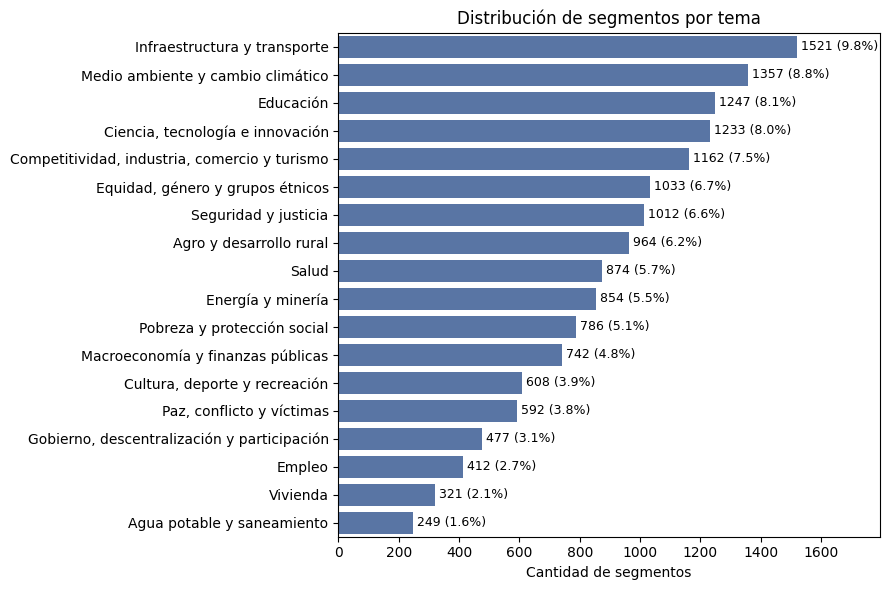

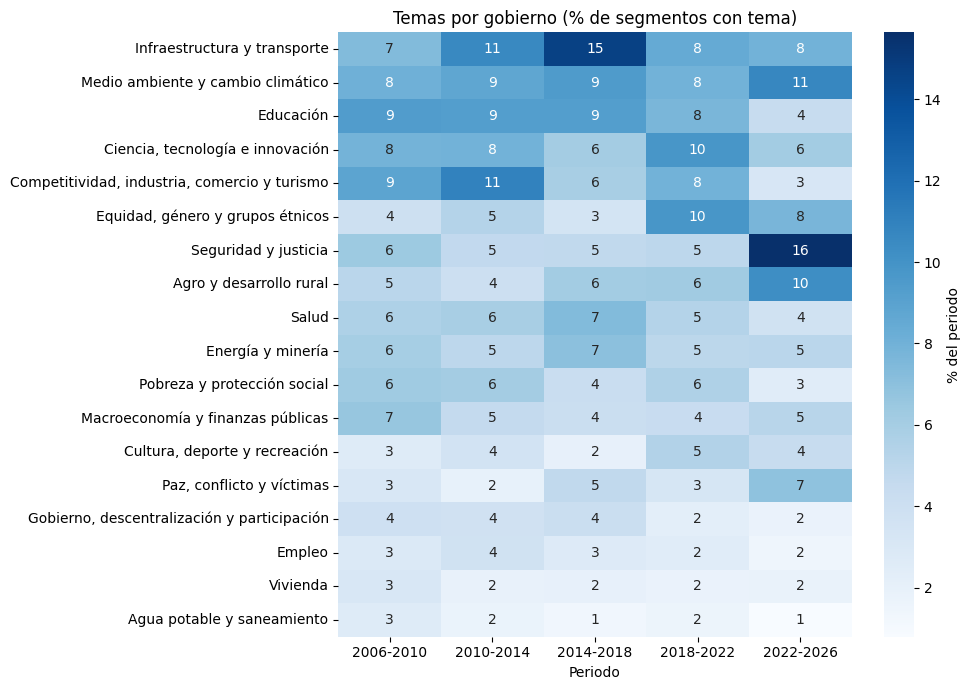

periodo
2006-2010    100.0
2010-2014    100.0
2014-2018    100.0
2018-2022    100.0
2022-2026    100.0
dtype: float64


In [17]:
# Manejo de datos y gráficos
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Etiqueta de los segmentos sin tema clasificable
OTROS = "Otros / sin tema claro"

# Carga todo el corpus limpio y separa los segmentos con tema claro (los "Otros" se excluyen)
df_all = pd.read_csv("corpus/segm_clasificados_limpios.csv")
df = df_all[df_all["tema_principal"] != OTROS].copy()

# Reporte de cuántos segmentos se excluyen y cuántos se analizan
print(f"Total de segmentos: {len(df_all)}")
print(f"Sin tema claro (excluidos): {len(df_all) - len(df)} ({(len(df_all) - len(df)) / len(df_all):.1%})")
print(f"Segmentos analizados: {len(df)}\n")

# ---------- Distribución de clases recalculada ----------
dist = (df["tema_principal"].value_counts()
          .rename_axis("tema").reset_index(name="segmentos"))
dist["porcentaje"] = (100 * dist["segmentos"] / dist["segmentos"].sum()).round(1)
print(dist.to_string(index=False))
print(f"\nSuma de porcentajes: {dist['porcentaje'].sum():.1f}")

# Orden de los temas de mayor a menor frecuencia (se reutiliza en las gráficas)
orden = dist["tema"].tolist()

# ---------- Gráfica 1: distribución de segmentos por tema ----------
plt.figure(figsize=(9, 6))
ax = sns.countplot(y="tema_principal", data=df, order=orden, color="#4c72b0")
# Etiqueta cada barra con su conteo y porcentaje
for i, (n, p) in enumerate(zip(dist["segmentos"], dist["porcentaje"])):
    ax.text(n, i, f" {n} ({p}%)", va="center", fontsize=9)
ax.set_xlim(0, dist["segmentos"].max() * 1.18)
plt.title("Distribución de segmentos por tema")
plt.xlabel("Cantidad de segmentos"); plt.ylabel("")
plt.tight_layout(); plt.show()

# ---------- Gráfica 2: temas por gobierno (% dentro de cada periodo) ----------
# % de cada tema dentro de cada periodo (cada columna suma 100)
tabla = pd.crosstab(df["tema_principal"], df["periodo"], normalize="columns") * 100
plt.figure(figsize=(10, 7))
sns.heatmap(tabla.loc[orden], annot=True, fmt=".0f", cmap="Blues",
            cbar_kws={"label": "% del periodo"})
plt.title("Temas por gobierno (% de segmentos con tema)")
plt.xlabel("Periodo"); plt.ylabel("")
plt.tight_layout(); plt.show()

# Verificación: cada columna del heatmap suma 100
print(tabla.sum().round(1))

### VI.2 Verificación por periodo

Cantidad de segmentos con tema "Otros" y su proporción por cada periodo.

In [18]:
  # Segmentos con tema por periodo
  print(df.groupby("periodo").size())
  # Proporción de segmentos "Otros" por periodo (sobre el total de cada periodo)
  print((df_all.groupby("periodo")["tema_principal"]
           .apply(lambda s: (s == OTROS).mean())).round(2))   # % de "Otros" por periodo

periodo
2006-2010    2143
2010-2014    2631
2014-2018    3091
2018-2022    5444
2022-2026    2135
dtype: int64
periodo
2006-2010    0.49
2010-2014    0.46
2014-2018    0.45
2018-2022    0.45
2022-2026    0.38
Name: tema_principal, dtype: float64


In [19]:
# Escribe aquí tu análisis con spaCy, WordCloud o visualizaciones...
# Descarga el modelo de spaCy para español
!python -m spacy download es_core_news_sm
# Stemmer para agrupar palabras de la misma raíz
from nltk.stem import SnowballStemmer
# spaCy: POS tagging, lematización y reconocimiento de entidades (NER)
import spacy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.9/12.9 MB 79.6 MB/s  0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('es_core_news_sm')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.


In [20]:
# Utilidades estándar
import re, math
from collections import Counter, defaultdict
from pathlib import Path

# Datos y gráficos
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# NLP
import spacy
from spacy import displacy
from nltk.stem import SnowballStemmer
# Nubes de palabras
from wordcloud import WordCloud

### VI.3 Configuración y carga de datos

Parámetros del análisis y validación de las columnas de texto y de clase.

In [21]:
# Archivo de entrada y nombres de columnas
ENTRADA    = Path("corpus/segm_clasificados_limpios.csv")   # Ajustado para usar la carpeta corpus/
COL_TEXTO  = "clean_text"
COL_CLASE  = None            # p. ej. "tema_principal"; si es None se intenta detectar
COL_NER    = "texto"         # columna con el texto original para NER (se ignora si no existe)
OTROS      = "Otros / sin tema claro"

# Carpeta donde se guardan las figuras
FIGURAS = Path("corpus/figuras"); FIGURAS.mkdir(parents=True, exist_ok=True)
# MUESTRA permite probar el flujo con un subconjunto de segmentos
MUESTRA = None               # p. ej. 2000 para probar rápido
# Categorías gramaticales con contenido semántico que se conservan para el análisis de palabras
POS_CONTENIDO = {"NOUN", "PROPN", "ADJ", "VERB"}
# USAR_STEM: agrupa por raíz | TOP_PALABRAS: máximo de palabras por nube
USAR_STEM, TOP_PALABRAS = True, 100

# Stopwords propias del dominio: palabras muy frecuentes en los PND que no distinguen temas
STOP_DOMINIO = {"colombia", "colombiano", "colombiana", "país", "nacional", "plan", "desarrollo",
                "gobierno", "año", "parte", "ser", "estar", "haber", "hacer", "tener", "poder",
                "deber", "dar", "ir", "contar", "permitir", "lograr", "realizar", "así",
                "nuevo", "mayor", "mejor", "público", "social", "general", "través"}

# Traducción de las etiquetas POS al español para las gráficas
POS_ES = {"NOUN": "Sustantivo", "PROPN": "Nombre propio", "VERB": "Verbo", "ADJ": "Adjetivo",
          "ADP": "Preposición", "DET": "Determinante", "AUX": "Auxiliar", "ADV": "Adverbio",
          "CCONJ": "Conj. coordinante", "SCONJ": "Conj. subordinante", "PRON": "Pronombre",
          "NUM": "Numeral", "X": "Otro", "SYM": "Símbolo", "INTJ": "Interjección", "PART": "Partícula"}

# Carga y validación de los datos
df = pd.read_csv(ENTRADA)
print("Columnas del archivo:", list(df.columns))

# --- Detectar la columna de clases ---
if COL_CLASE is None:
    for c in ["tema_principal", "tema", "clase", "label", "categoria", "categoría"]:
        if c in df.columns:
            COL_CLASE = c; break
assert COL_TEXTO in df.columns, f"No existe la columna {COL_TEXTO}"
assert COL_CLASE in df.columns, "Indica COL_CLASE con el nombre de tu columna de clases"

# Elimina textos vacíos y segmentos sin tema claro; opcionalmente toma una muestra
df = df[df[COL_TEXTO].notna() & (df[COL_TEXTO].str.strip() != "")]
df = df[df[COL_CLASE] != OTROS].reset_index(drop=True)
if MUESTRA:
    df = df.sample(MUESTRA, random_state=42).reset_index(drop=True)

# --- Diagnóstico: ¿clean_text conserva mayúsculas? ---
muestra_txt = " ".join(df[COL_TEXTO].head(500))
pct_mayus = sum(c.isupper() for c in muestra_txt) / max(sum(c.isalpha() for c in muestra_txt), 1)
# Si clean_text ya está en minúsculas, el NER usará la columna original (con mayúsculas)
CONSERVA_MAYUS = pct_mayus > 0.01
usar_original = (COL_NER in df.columns) and (not CONSERVA_MAYUS or COL_NER != COL_TEXTO)
COL_PARA_NER = COL_NER if usar_original else COL_TEXTO

print(f"Segmentos: {len(df)} | mayúsculas en {COL_TEXTO}: {pct_mayus:.1%}")
print(f"NER se aplicará sobre: {COL_PARA_NER}")
if not CONSERVA_MAYUS and not usar_original:
    print("⚠ Sin mayúsculas y sin columna original: el NER detectará muy pocas entidades.")

Columnas del archivo: ['periodo', 'pagina', 'clean_text', 'tema_principal', 'tema_secundario']
Segmentos: 15444 | mayúsculas en clean_text: 0.0%
NER se aplicará sobre: clean_text
⚠ Sin mayúsculas y sin columna original: el NER detectará muy pocas entidades.


### VI.4 Procesamiento con spaCy: POS, lemas y entidades

Pasada 1 sobre el texto limpio (POS y lemas) y pasada 2 sobre el texto original con mayúsculas (NER).

In [22]:
# Modelo en español; se desactiva el parser de dependencias (no se usa) para ir más rápido
nlp = spacy.load("es_core_news_sm", disable=["parser"])
stemmer = SnowballStemmer("spanish")
stop_spacy = nlp.Defaults.stop_words

# Contadores por tema: POS, palabras clave (por raíz), lema más frecuente por raíz y entidades
pos_por_tema    = defaultdict(Counter)
claves_por_tema = defaultdict(Counter)
lemas_por_clave = defaultdict(Counter)
ents_por_tema   = defaultdict(Counter)
lemas_seg = []

# --- Pasada 1: POS + lemas (sobre clean_text) ---
for tema, doc in zip(df[COL_CLASE], nlp.pipe(df[COL_TEXTO].tolist(), batch_size=64)):
    lemas = []
    for t in doc:
        # Ignora espacios y signos de puntuación
        if t.is_space or t.is_punct:
            continue
        # Cuenta cada token por categoría gramatical
        pos_por_tema[tema][t.pos_] += 1
        # Conserva solo palabras de contenido (sustantivos, adjetivos, verbos) que no sean stopwords
        if t.pos_ in POS_CONTENIDO and t.is_alpha and not t.is_stop:
            l = t.lemma_.lower()
            if len(l) > 2 and l not in stop_spacy and l not in STOP_DOMINIO:
                # "clave" es la raíz de la palabra (agrupa variantes); luego se muestra su lema más frecuente
                clave = stemmer.stem(l) if USAR_STEM else l
                claves_por_tema[tema][clave] += 1
                lemas_por_clave[clave][l] += 1
                lemas.append(l)
    lemas_seg.append(" ".join(lemas))

# --- Pasada 2: NER (sobre el texto con mayúsculas si existe) ---
ents_seg = []
# Con texto original se exige que la entidad empiece en mayúscula (reduce falsos positivos)
exigir_mayus = COL_PARA_NER == COL_NER and usar_original or CONSERVA_MAYUS
for tema, doc in zip(df[COL_CLASE], nlp.pipe(df[COL_PARA_NER].fillna("").tolist(), batch_size=64)):
    ents = []
    for e in doc.ents:
        txt = re.sub(r"\s+", " ", e.text).strip()
        if len(txt) >= 3 and (not exigir_mayus or txt[0].isupper()):
            ents_por_tema[tema][(txt, e.label_)] += 1
            ents.append(f"{txt} ({e.label_})")
    ents_seg.append(" | ".join(ents))

# Guarda lemas y entidades por segmento y exporta el resultado
df["lemas"] = lemas_seg
df["entidades"] = ents_seg
df.to_csv("corpus/segmentos_spacy.csv", index=False, encoding="utf-8-sig")

### VI.5 Ejemplo de análisis morfológico

In [23]:
# Ejemplo: análisis token a token del primer segmento (POS, lema y morfología)
doc_ej = nlp(df[COL_TEXTO].iloc[0][:400])
pd.DataFrame([(t.text, t.pos_, POS_ES.get(t.pos_, t.pos_), t.lemma_, str(t.morph))
              for t in doc_ej if not t.is_space],
             columns=["token", "POS", "categoría", "lema", "morfología"]).head(15)

,token,POS,categoría,lema,morfología
0,dentro,ADV,Adverbio,dentro,
1,marco,NOUN,Sustantivo,marco,Gender=Masc|Number=Sing
2,general,ADJ,Adjetivo,general,Number=Sing
3,impuesto,ADJ,Adjetivo,impuesto,Gender=Masc|Number=Sing|VerbForm=Part
4,constitución,PROPN,Nombre propio,constitución,
5,define,VERB,Verbo,definir,Mood=Ind|Number=Sing|Person=3|Tense=Pres|VerbF...
6,colombia,PROPN,Nombre propio,colombia,
7,social,ADJ,Adjetivo,social,Number=Sing
8,derecho,NOUN,Sustantivo,derecho,Gender=Masc|Number=Sing
9,aquí,ADV,Adverbio,aquí,


### VI.6 Distribución de categorías gramaticales (POS)

Porcentaje global de cada categoría y comparación entre temas.

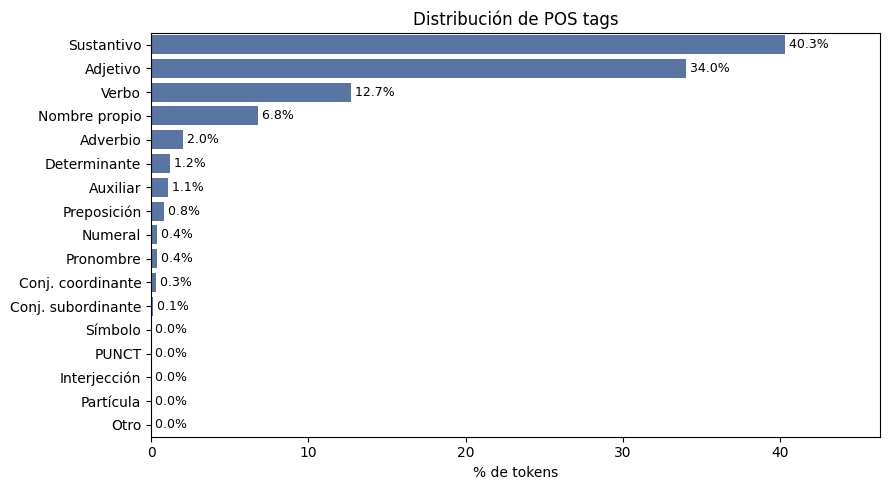

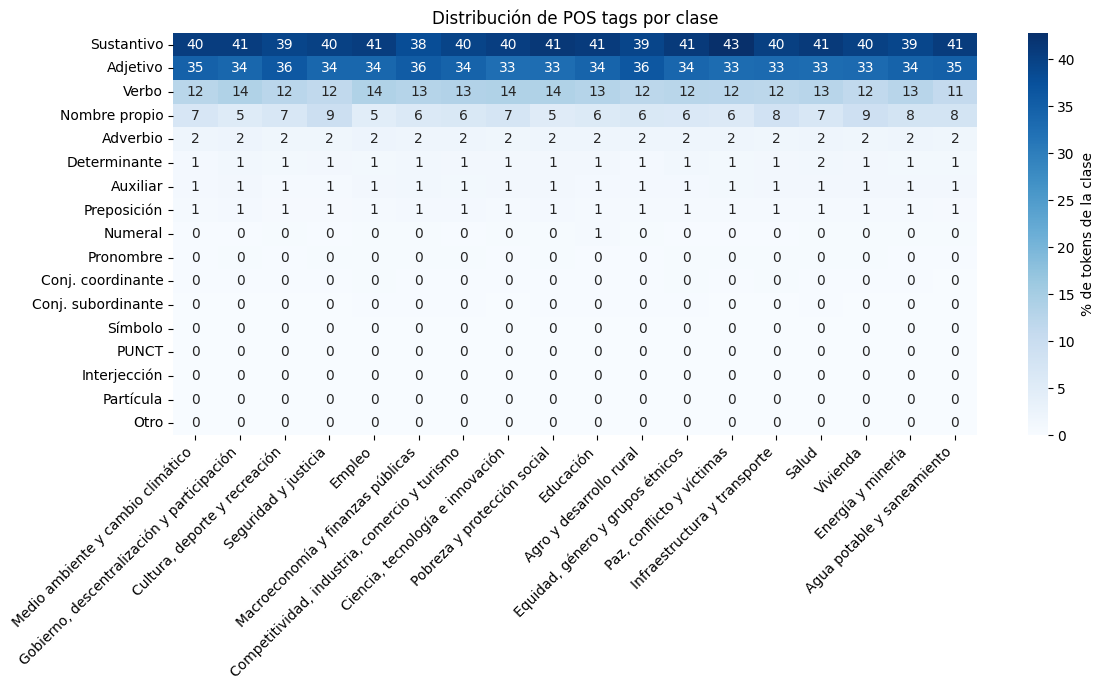

In [24]:
# Matriz POS x tema con conteos, ordenada por frecuencia total
pos_df = pd.DataFrame(pos_por_tema).fillna(0).astype(int)
pos_df = pos_df.loc[pos_df.sum(axis=1).sort_values(ascending=False).index]

# a) Global
glob_pct = (100 * pos_df.sum(axis=1) / pos_df.values.sum()).round(1)
plt.figure(figsize=(9, 5))
ax = sns.barplot(x=glob_pct.values, y=[POS_ES.get(p, p) for p in glob_pct.index], color="#4c72b0")
for i, v in enumerate(glob_pct.values):
    ax.text(v, i, f" {v}%", va="center", fontsize=9)
ax.set_xlim(0, glob_pct.max() * 1.15)
plt.title("Distribución de POS tags"); plt.xlabel("% de tokens"); plt.ylabel("")
plt.tight_layout(); plt.savefig(FIGURAS / "pos_global.png", dpi=150); plt.show()

# b) Por clase
# Porcentaje de cada POS dentro de cada tema (cada columna suma 100)
pos_pct = (pos_df / pos_df.sum() * 100).round(1)
pos_pct.index = [POS_ES.get(p, p) for p in pos_pct.index]
plt.figure(figsize=(12, 7))
sns.heatmap(pos_pct, annot=True, fmt=".0f", cmap="Blues", cbar_kws={"label": "% de tokens de la clase"})
plt.title("Distribución de POS tags por clase"); plt.xlabel(""); plt.ylabel("")
plt.xticks(rotation=45, ha="right")
plt.tight_layout(); plt.savefig(FIGURAS / "pos_por_tema.png", dpi=150); plt.show()

### VI.7 Entidades nombradas (NER)

Entidades más frecuentes de todo el corpus, por tipo (personas, organizaciones, lugares y misceláneo).

etiqueta
LOC     3063
MISC    1119
ORG     1033
PER     4017
Name: menciones, dtype: int64


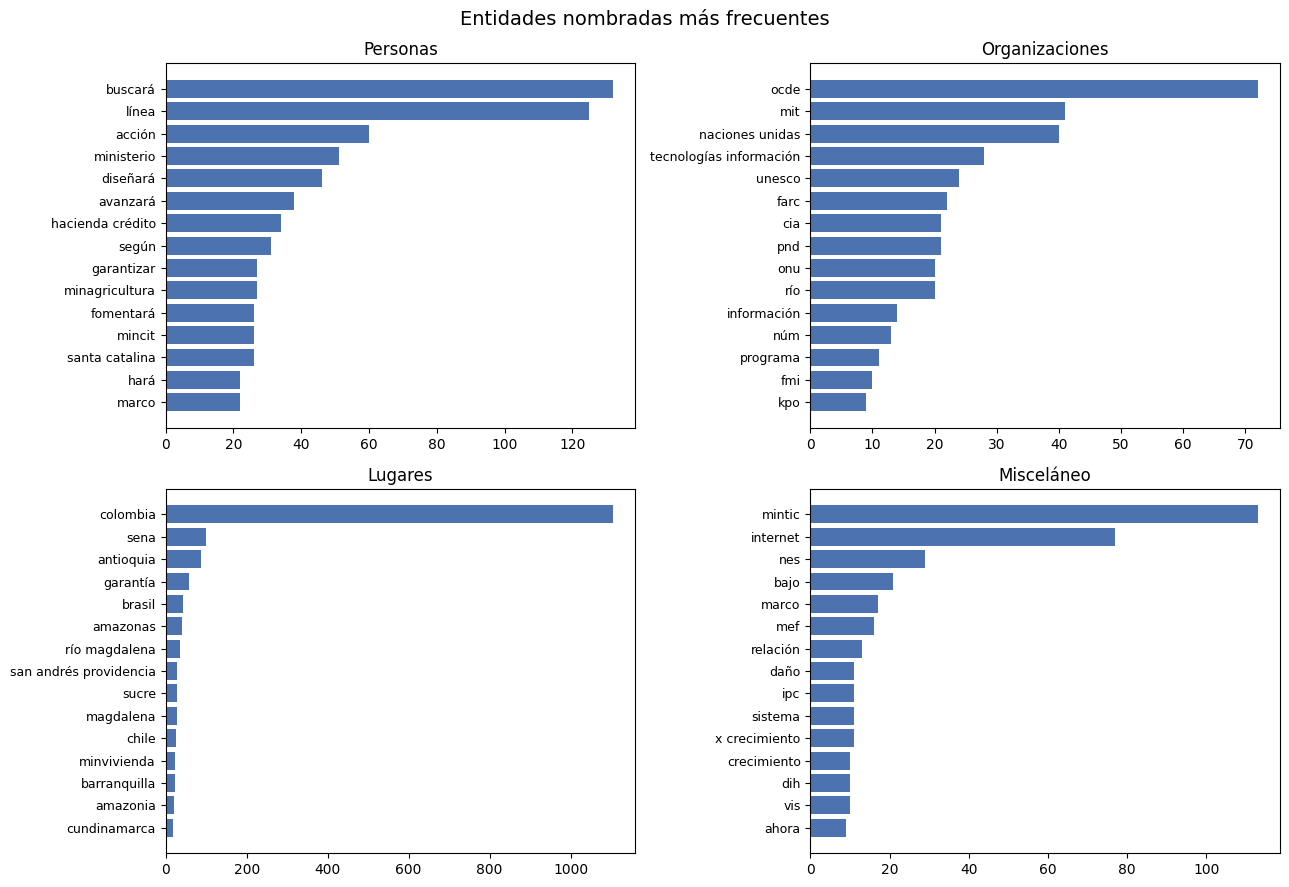

In [25]:
# Tabla en formato largo: tema, entidad, etiqueta y frecuencia
ents_df = pd.DataFrame(
    [(tema, txt, lab, c) for tema, cnt in ents_por_tema.items() for (txt, lab), c in cnt.items()],
    columns=["tema", "entidad", "etiqueta", "frecuencia"])
ents_df.to_csv("corpus/entidades_por_tema.csv", index=False, encoding="utf-8-sig")

# Frecuencia total de cada entidad en todo el corpus
top = ents_df.groupby(["etiqueta", "entidad"], as_index=False).frecuencia.sum()
print(top.groupby("etiqueta").frecuencia.sum().rename("menciones"))

# Tipos de entidad que detecta spaCy en español
ETIQ = {"PER": "Personas", "ORG": "Organizaciones", "LOC": "Lugares", "MISC": "Misceláneo"}
# Un panel por tipo de entidad con las 15 más frecuentes
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, (lab, nombre) in zip(axes.ravel(), ETIQ.items()):
    d = top[top.etiqueta == lab].nlargest(15, "frecuencia").iloc[::-1]
    ax.barh(d["entidad"], d["frecuencia"], color="#4c72b0")
    ax.set_title(nombre); ax.tick_params(axis="y", labelsize=9)
plt.suptitle("Entidades nombradas más frecuentes", fontsize=14)
plt.tight_layout(); plt.savefig(FIGURAS / "ner_top.png", dpi=150); plt.show()

# Segmento con entidades resaltadas
idx = df.index[df["entidades"] != ""]
if len(idx):
    displacy.render(nlp(df.loc[idx[0], COL_PARA_NER]), style="ent", jupyter=True)

### VI.8 Entidades por tema (tablas)

Top 20 de entidades en Educación, Vivienda y Empleo.

In [26]:
# Temas que se van a comparar
CLASES = ["Educación", "Vivienda", "Empleo"]

# Tabla con las 20 entidades más frecuentes de cada tema
for clase in CLASES:
    print(f"\n=== {clase} ===")
    display(
        ents_df[ents_df.tema == clase]
        .nlargest(20, "frecuencia")
        .reset_index(drop=True)[["entidad", "etiqueta", "frecuencia"]]
    )


=== Educación ===


,entidad,etiqueta,frecuencia
0,colombia,LOC,94
1,sena,LOC,54
2,ministerio,PER,42
3,mef,MISC,12
4,secretarías,PER,11
5,mineducación,PER,11
6,buscará,PER,10
7,línea,PER,10
8,diseñará,PER,9
9,ocde,ORG,8



=== Vivienda ===


,entidad,etiqueta,frecuencia
0,naciones unidas,ORG,10
1,vis,MISC,9
2,colombia,LOC,5
3,acción,PER,5
4,línea,PER,4
5,unesco,ORG,4
6,protección uoa,ORG,4
7,avanzará,PER,3
8,minvivienda,LOC,3
9,vis,ORG,2



=== Empleo ===


,entidad,etiqueta,frecuencia
0,colombia,LOC,26
1,sena,LOC,6
2,línea,PER,5
3,ocde,ORG,5
4,mintrabajo,LOC,5
5,jun,MISC,4
6,diseñará,PER,4
7,minsalud,PER,3
8,buscará,PER,3
9,trabajará,PER,2


### VI.9 Entidades por tema (gráficas Top 10)

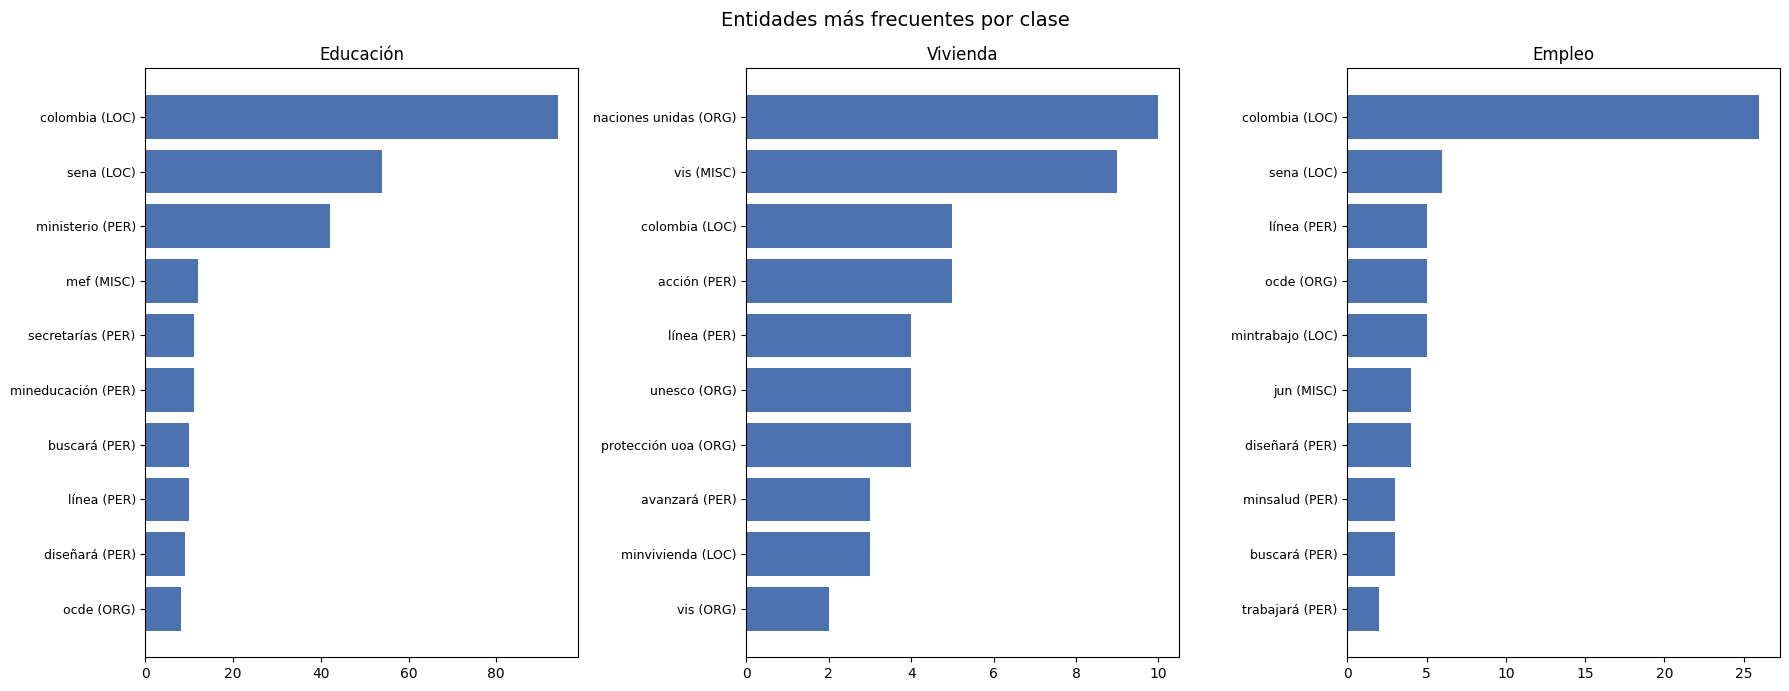

In [27]:
# Un panel por tema con sus 10 entidades más frecuentes
fig, axes = plt.subplots(1, 3, figsize=(18, 7))
for ax, clase in zip(axes, CLASES):
    d = (ents_df[ents_df.tema == clase]
         .nlargest(10, "frecuencia")
         .iloc[::-1])
    ax.barh(d["entidad"] + " (" + d["etiqueta"] + ")", d["frecuencia"], color="#4c72b0")
    ax.set_title(clase)
    ax.tick_params(axis="y", labelsize=9)
plt.suptitle("Entidades más frecuentes por clase", fontsize=14)
plt.tight_layout()
plt.savefig(FIGURAS / "ner_educacion_vivienda_empleo.png", dpi=150)
plt.show()

### VI.10 Nubes de palabras por tema

Palabras clave más frecuentes por tema, agrupadas por raíz y mostradas con su lema más común.

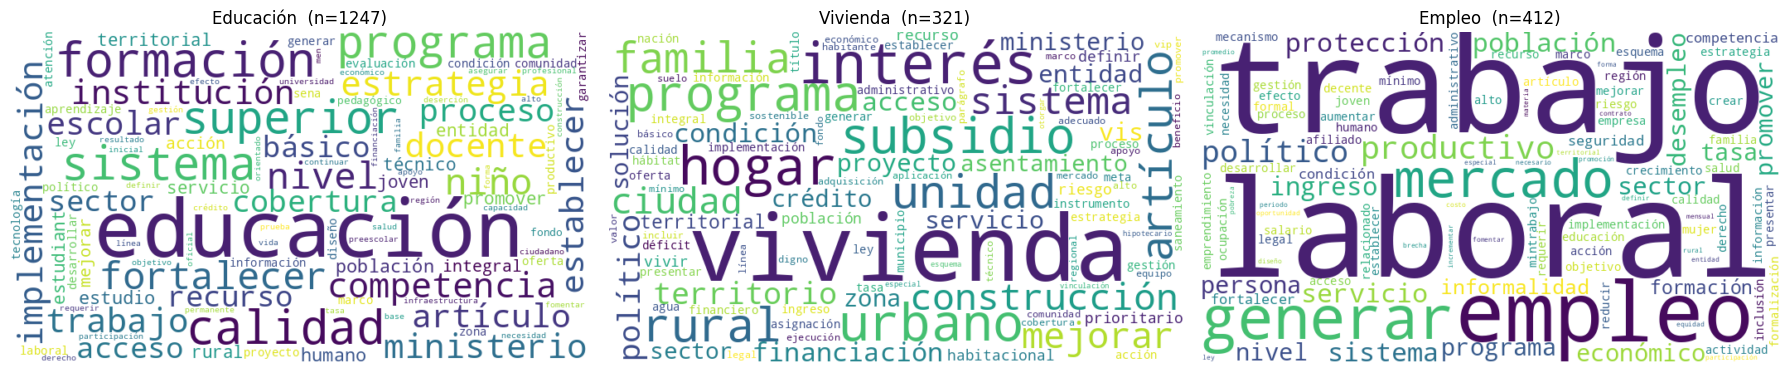

In [28]:
CLASES = ["Educación", "Vivienda", "Empleo"]

# Devuelve {lema: frecuencia} de las palabras clave más frecuentes de un tema
def frecuencias(tema, n=TOP_PALABRAS):
    out = Counter()
    for clave, c in claves_por_tema[tema].most_common(n):
        out[lemas_por_clave[clave].most_common(1)[0][0]] += c
    return dict(out)

# Una nube de palabras por tema
fig, axes = plt.subplots(1, len(CLASES), figsize=(6 * len(CLASES), 4.2))

for ax, tema in zip(axes, CLASES):
    freqs = frecuencias(tema)
    if freqs:
        wc = WordCloud(width=700, height=400, background_color="white", colormap="viridis",
                       max_words=TOP_PALABRAS, random_state=42).generate_from_frequencies(freqs)
        ax.imshow(wc, interpolation="bilinear")
        # Guarda cada nube como imagen independiente
        wc.to_file(FIGURAS / f"nube_{re.sub(r'[^A-Za-z0-9]+', '_', tema)}.png")
    else:
        ax.text(0.5, 0.5, "Sin datos", ha="center", va="center")
    ax.set_title(f"{tema}  (n={(df[COL_CLASE] == tema).sum()})", fontsize=12)
    ax.axis("off")

plt.tight_layout()
plt.savefig(FIGURAS / "nubes_educacion_vivienda_empleo.png", dpi=130)
plt.show()

# Parte VII · Modelado: clasificación de temas

Se entrena un clasificador de texto con TF-IDF y regresión logística. Primero con todos los temas  y luego con un subconjunto de tres clases.

### VII.A.1 Librerías y parámetros

In [29]:
# Manejo de datos y gráficos
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Aplica TfidfVectorizer, entrena el modelo, y evalúa...
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

# Parámetros: archivo, columna de texto, variable objetivo y mínimo de ejemplos por clase
ENTRADA   = "corpus/segm_clasificados_limpios.csv"
COL_TEXTO = "clean_text"
COL_Y     = "tema_principal"        # ¡¡¡ En caso de implementar columna de sentimiento !!!
OTROS     = "Otros / sin tema claro"
MIN_CLASE = 30                       # clases con menos ejemplos se descartan

### VII.A.2 Carga de datos y partición entrenamiento/prueba

In [30]:
# Carga y filtrado: sin textos vacíos, sin "Otros" y sin clases con pocos ejemplos
df = pd.read_csv(ENTRADA)
df = df[df[COL_TEXTO].notna() & (df[COL_TEXTO].str.strip() != "")]
df = df[df[COL_Y] != OTROS]

conteo = df[COL_Y].value_counts()
df = df[df[COL_Y].isin(conteo[conteo >= MIN_CLASE].index)].reset_index(drop=True)

# Distribución de las clases que se conservan
print(df[COL_Y].value_counts())

# Partición 80/20 estratificada (mantiene la proporción de clases) y reproducible
X_train, X_test, y_train, y_test = train_test_split(
    df[COL_TEXTO], df[COL_Y],
    test_size=0.2, stratify=df[COL_Y], random_state=42)

tema_principal
Infraestructura y transporte                     1521
Medio ambiente y cambio climático                1357
Educación                                        1247
Ciencia, tecnología e innovación                 1233
Competitividad, industria, comercio y turismo    1162
Equidad, género y grupos étnicos                 1033
Seguridad y justicia                             1012
Agro y desarrollo rural                           964
Salud                                             874
Energía y minería                                 854
Pobreza y protección social                       786
Macroeconomía y finanzas públicas                 742
Cultura, deporte y recreación                     608
Paz, conflicto y víctimas                         592
Gobierno, descentralización y participación       477
Empleo                                            412
Vivienda                                          321
Agua potable y saneamiento                        249
Name: count, 

### VII.A.3 Vectorización TF-IDF

In [31]:
# TF-IDF con unigramas y bigramas; min_df/max_df descartan términos muy raros o muy comunes; sublinear_tf suaviza frecuencias altas
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=5, max_df=0.5,
                        sublinear_tf=True, max_features=50_000)

X_train_tfidf = tfidf.fit_transform(X_train)   # aprende vocabulario SOLO con entrenamiento
X_test_tfidf  = tfidf.transform(X_test)        # aplica ese mismo vocabulario a prueba

print("Matriz de entrenamiento:", X_train_tfidf.shape)
print("Matriz de prueba:", X_test_tfidf.shape)


Matriz de entrenamiento: (12355, 20016)
Matriz de prueba: (3089, 20016)


### VII.A.4 Entrenamiento del modelo

In [32]:
# Regresión logística; class_weight="balanced" compensa el desbalance entre clases
modelo = LogisticRegression(max_iter=1000, C=1.0, class_weight="balanced")
modelo.fit(X_train_tfidf, y_train)

LogisticRegression(class_weight='balanced', max_iter=1000)

### VII.A.5 Evaluación

In [33]:
# Predice sobre el conjunto de prueba y muestra precisión, recall y F1 por clase
y_pred = modelo.predict(X_test_tfidf)
print(classification_report(y_test, y_pred, digits=3, zero_division=0))

                                               precision    recall  f1-score   support

                      Agro y desarrollo rural      0.917     0.798     0.853       193
                   Agua potable y saneamiento      0.810     0.940     0.870        50
             Ciencia, tecnología e innovación      0.932     0.887     0.909       247
Competitividad, industria, comercio y turismo      0.882     0.905     0.894       232
                Cultura, deporte y recreación      0.827     0.902     0.863       122
                                    Educación      0.945     0.832     0.885       250
                                       Empleo      0.819     0.829     0.824        82
                            Energía y minería      0.891     0.906     0.899       171
             Equidad, género y grupos étnicos      0.880     0.918     0.898       207
  Gobierno, descentralización y participación      0.736     0.853     0.790        95
                 Infraestructura y transpo

### VII.A.6 Matriz de confusión

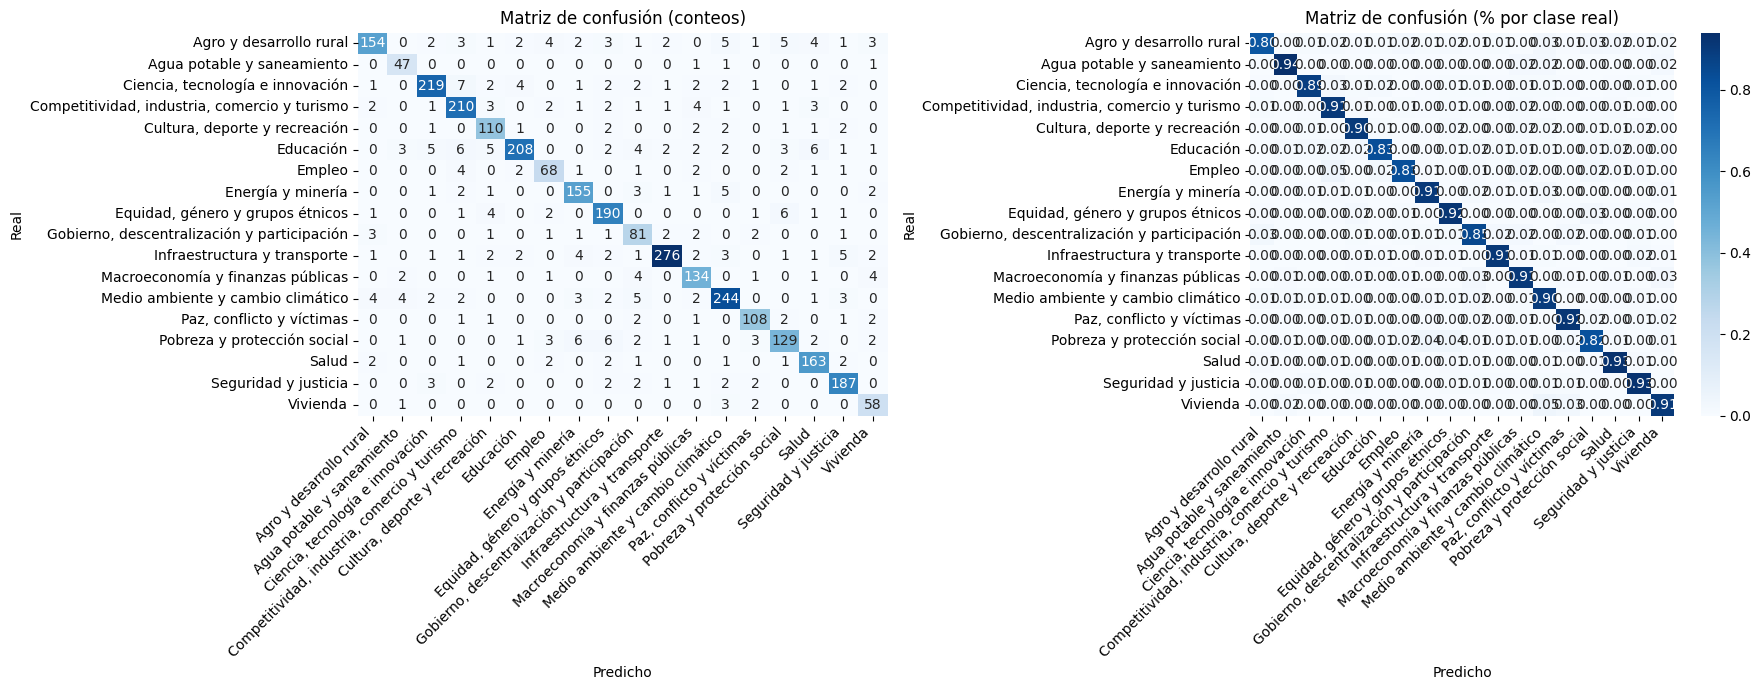

In [34]:
# Matriz de confusión en conteos y normalizada por clase real
clases = sorted(y_test.unique())
cm = confusion_matrix(y_test, y_pred, labels=clases)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=clases, yticklabels=clases, ax=axes[0])
axes[0].set_title("Matriz de confusión (conteos)")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=clases, yticklabels=clases, ax=axes[1])
axes[1].set_title("Matriz de confusión (% por clase real)")

# Etiquetas de los ejes y rotación de los nombres de clase
for ax in axes:
    ax.set_xlabel("Predicho"); ax.set_ylabel("Real")
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
plt.tight_layout(); plt.show()

### VII.A.7 Términos más influyentes por clase

In [35]:
import numpy as np

# Términos con mayor coeficiente por clase: los que más pesan en la predicción
vocab = np.array(tfidf.get_feature_names_out())
coefs = modelo.coef_
if len(modelo.classes_) == 2:                  # caso binario: un solo vector de coeficientes
    coefs = np.vstack([-coefs[0], coefs[0]])

for clase, c in zip(modelo.classes_, coefs):
    print(f"{clase:45s} → {', '.join(vocab[np.argsort(c)[-12:][::-1]])}")

Agro y desarrollo rural                       → rural, rurales, agropecuario, agricultura, agropecuaria, cultivos, desarrollo rural, agropecuarios, campesinos, campesinas, agropecuarias, producción
Agua potable y saneamiento                    → saneamiento, acueducto, alcantarillado, agua, acueducto alcantarillado, agua potable, potable, potable saneamiento, básico, saneamiento básico, tratamiento, acueductos
Ciencia, tecnología e innovación              → innovación, tecnologías, digital, tecnología, tic, investigación, ciencia, internet, ciencia tecnología, tecnológica, colciencias, tecnológico
Competitividad, industria, comercio y turismo → empresas, comercio, productividad, competitividad, turismo, industria, empresarial, emprendimiento, exportaciones, empresa, empresariales, industrial
Cultura, deporte y recreación                 → cultura, deporte, culturales, cultural, patrimonio, recreación, naranja, deportivos, economía naranja, deportiva, patrimonio cultural, bibliotecas
Ed

### VII.A.8 Predicción con texto nuevo

**Texto ejemplo**

Se clasifican textos nuevos aplicando el mismo preprocesamiento del entrenamiento y respetando el largo de los segmentos del corpus (20 palabras o más y 2.000 caracteres o menos).


| Tema | Texto |
|---|---|
| Educación | "gobierno fortalecerá educación básica media docentes mejores escuelas ampliará cobertura escolar reducirá deserción estudiantes mejorará calidad aprendizaje mediante jornada única formación maestros instituciones educativas país" |
| Vivienda | "promoverá acceso vivienda interés social subsidios habitacionales mejoramiento barrios. programa reducirá déficit cuantitativo cualitativo vivienda, facilitará crédito hipotecario familias menores ingresos legalizará asentamientos informales ciudades" |
| Empleo | "política laboral buscará reducir desempleo informalidad mercado laboral promoverá generación empleo formal empleabilidad jóvenes trabajo decente mejores salarios mayor protección trabajadores aumentar tasa  ocupación" |
| Mixto | "educación técnica mejora empleabilidad jóvenes también requiere vivienda cerca centros trabajo familias necesitan acceso servicios básicos poder estudiar trabajar estabilidad" |


In [46]:
  # Ejemplo de uso: clasificar un texto nuevo (debe tener el mismo preprocesamiento que el entrenamiento)
  nuevo = ["educación técnica mejora empleabilidad jóvenes también requiere vivienda cerca centros trabajo familias necesitan acceso servicios básicos poder estudiar trabajar estabilidad"]
  modelo.predict(tfidf.transform(nuevo))

array(['Educación'], dtype=object)

In [47]:
#Probabilidad de las 3 clases dentro del nuevo texto
probs = modelo.predict_proba(tfidf.transform(nuevo))[0]
print(pd.Series(probs, index=modelo.classes_).sort_values(ascending=False).head(5))

Educación    0.363308
Vivienda     0.334675
Empleo       0.302018
dtype: float64


## Vectorización y entrenamiento con 3 clases

### VII.B.1 Librerías y parámetros

In [37]:
# Manejo de datos, gráficos y modelado
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

# Parámetros: se trabaja solo con tres temas
ENTRADA   = "corpus/segm_clasificados_limpios.csv"
COL_TEXTO = "clean_text"
COL_Y     = "tema_principal"
CLASES    = ["Educación", "Vivienda", "Empleo"]

### VII.B.2 Carga de datos y partición entrenamiento/prueba

In [38]:
# Carga y filtra las 3 clases de interés
df = pd.read_csv(ENTRADA)
df = df[df[COL_TEXTO].notna() & (df[COL_TEXTO].str.strip() != "")]
df = df[df[COL_Y].isin(CLASES)].reset_index(drop=True)

print(df[COL_Y].value_counts())
print(df[COL_Y].value_counts(normalize=True).round(3))

# Partición 80/20 estratificada
X_train, X_test, y_train, y_test = train_test_split(
    df[COL_TEXTO], df[COL_Y],
    test_size=0.2, stratify=df[COL_Y], random_state=42)

tema_principal
Educación    1247
Empleo        412
Vivienda      321
Name: count, dtype: int64
tema_principal
Educación    0.630
Empleo       0.208
Vivienda     0.162
Name: proportion, dtype: float64


### VII.B.3 Vectorización TF-IDF y entrenamiento

In [39]:
# TF-IDF con umbral más bajo (min_df=3) y vocabulario máximo de 30.000 términos
tfidf = TfidfVectorizer(ngram_range=(1, 2), min_df=3, max_df=0.5,
                        sublinear_tf=True, max_features=30_000)

X_train_tfidf = tfidf.fit_transform(X_train)   # vocabulario solo con entrenamiento
X_test_tfidf  = tfidf.transform(X_test)
print("Matriz de entrenamiento:", X_train_tfidf.shape)

# Regresión logística con pesos balanceados
modelo = LogisticRegression(max_iter=1000, C=1.0, class_weight="balanced")
modelo.fit(X_train_tfidf, y_train)

Matriz de entrenamiento: (1584, 6226)


LogisticRegression(class_weight='balanced', max_iter=1000)

### VII.B.4 Evaluación y matriz de confusión

              precision    recall  f1-score   support

   Educación      0.992     0.976     0.984       250
      Empleo      0.941     0.976     0.958        82
    Vivienda      0.969     0.984     0.977        64

    accuracy                          0.977       396
   macro avg      0.967     0.979     0.973       396
weighted avg      0.978     0.977     0.977       396



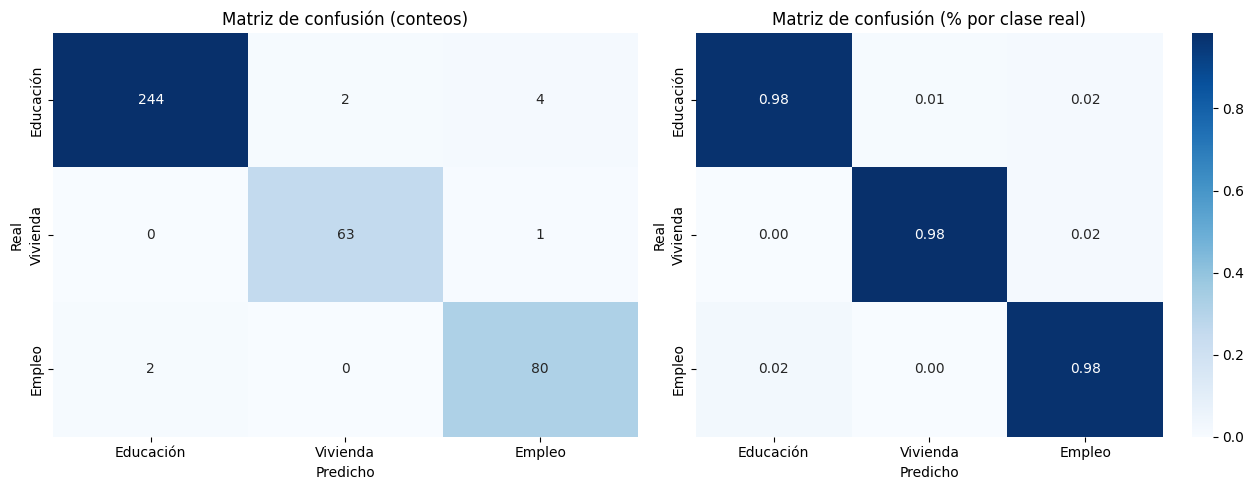

In [40]:
# Evaluación sobre el conjunto de prueba
y_pred = modelo.predict(X_test_tfidf)
print(classification_report(y_test, y_pred, digits=3, zero_division=0))

# Matriz de confusión: conteos y proporción por clase real
cm = confusion_matrix(y_test, y_pred, labels=CLASES)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
            xticklabels=CLASES, yticklabels=CLASES, ax=axes[0])
axes[0].set_title("Matriz de confusión (conteos)")
sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
            xticklabels=CLASES, yticklabels=CLASES, ax=axes[1])
axes[1].set_title("Matriz de confusión (% por clase real)")
for ax in axes:
    ax.set_xlabel("Predicho"); ax.set_ylabel("Real")
plt.tight_layout(); plt.show()

### VII.B.5 Términos más influyentes por clase

In [41]:
# Términos más influyentes por clase
vocab = np.array(tfidf.get_feature_names_out())
for clase, c in zip(modelo.classes_, modelo.coef_):
    print(f"\n{clase}")
    print("  " + ", ".join(vocab[np.argsort(c)[-15:][::-1]]))


Educación
  educación, superior, educativo, estudiantes, formación, educación superior, docentes, educativos, educativa, escolar, educativas, media, calidad, sena, instituciones

Empleo
  laboral, empleo, trabajadores, laborales, desempleo, empleos, trabajo, informalidad, mercado, mintrabajo, mercado laboral, riesgos, personas, protección, ocupada

Vivienda
  vivienda, viviendas, vis, hogares, interés, asentamientos, interés social, vivienda interés, hábitat, déficit, subsidio, riesgo, vip, mejoramiento, agua


### VII.B.6 Análisis de errores

In [42]:
# Análisis de errores: texto, clase real y clase predicha
res = pd.DataFrame({"texto": X_test.values, "real": y_test.values, "predicho": y_pred})
errores = res[res.real != res.predicho]
# Cantidad de errores y confusiones más frecuentes
print(f"Errores: {len(errores)} de {len(res)} ({len(errores) / len(res):.1%})")
print(errores.groupby(["real", "predicho"]).size().sort_values(ascending=False))

# Muestra textos completos y 8 errores al azar
pd.set_option("display.max_colwidth", 300)
errores.sample(min(8, len(errores)), random_state=1)

Errores: 9 de 396 (2.3%)
real       predicho 
Educación  Empleo       4
           Vivienda     2
Empleo     Educación    2
Vivienda   Empleo       1
dtype: int64


,texto,real,predicho
379,promover mayor acceso mecanismos permitan certificación reconocimiento competencias laborales requisito idóneo acceder oportunidades laborales población ocupada desempleados adquirido conocimientos aptitudes destrezas través sfch mecanismos formales aprendizaje creará sistema nacional certificac...,Empleo,Educación
157,corresponde totalidad diálogos realizados subregiones cuales recolectaron necesidades cambio propuestas acción cambio diálogos principales temáticas mencionan comien realizados zan moldear aspectos abordados cada transfor subregiones mación consolidación vías terciarias ordenamiento recolectaron...,Educación,Vivienda
250,ello indujo empresas interior países comenzaran enfrentar mayores presiones competitividad consecuencia ello aumentaran demanda trabajo calificado evidencia colombia kugler señala incremento nivel calificación derivó complementariedad capitalcalificación tecnologíacalificación flujos capital tra...,Educación,Empleo
274,media dosis totales vivienda vivienda años infantil nacidos vacuna saber tributarios variables analfabetismo tasa acueducto cualitativo cuantitativo cobertura matemáticas dpt cobertura ingresos déficit déficit educación pruebas mortalidad x cobertura ingresos tasa,Educación,Vivienda
107,adicionalmente privaciones particularmente críticas población condición pobreza además altas población encuentra condición pobreza bajo logro educativo rezago escolar empleo informal tabla iii observa privaciones empleo informal bajo logro educativo analfabetismo trabajo infantil presentaron dis...,Educación,Empleo
72,parte población presenta menor nivel alfabetismo baja escolaridad menores tasas asistencia escolar debido fundamentalmente dificultades pertinencia acceso permanencia calidad ciclo educativo dificulta superación pobreza así mismo consecuencia baja calificación talento humano población grupos étn...,Educación,Empleo
200,construcción constituye gran apuesta aprovechar incremento demanda vivienda genera mayor dinamismo económico impulsar generación empleo especialmente zonas urbanas país así mismo sector vivienda dados eslabonamientos múltiples diversas actividades económicas potencial dinamizar economía impulsar...,Vivienda,Empleo
194,través servicio nacional brindará talleres orientación ocupacio nal permita identificar perfil ocupacional intereses ocupacionales fin identificar necesidades formación permita mejorar niveles empleabilidad inserción laboral,Empleo,Educación
